# Transfer-factor decomposition — do student-base animal priors explain cross-init transfer?

**The focus-20 campaign.** 20 fixed teacher recipes (one list, shared across animals *by design*)
are each cross-distilled into 6 PolyPythias student bases at 20 shared student-HP cells, for
**dog / cat / lion / pig**. Some (animal × student-base) cells transfer the trait well; others do
not. This notebook decomposes that pattern into interpretable factor groups and asks whether the
measured student-base *prior* — how much a base already likes an animal — explains it.

**The five factors:**

1. **Teacher imprint** — how strongly the teacher recipe carries the trait. A property of the
   *animal* (teacher list is identical across animals) ⇒ absorbed by an **animal fixed effect**
   (which also absorbs the *teacher-base* prior, since all teachers share pythia-160m).
2. **Teacher-base prior** — animal-level, folded into the animal FE (factor 1).
3. **Student-base prior `P_s(a)`** — a *measured* animal×base covariate; NOT absorbed by either FE
   and identified by the **within-animal cross-base contrast** (does base *s* over-perform its own
   average exactly on the animals it already favors?). Its coefficient `β` is the estimand of
   interest.
4. **ds-vs-ws structure** — do data-seed and weight-seed bases differ as *groups* after adjustment?
5. **Individual base quirks** — per-base fixed effects with/without the prior term.

> **Reading guide.** Collapse is read on the **integrity** channel: a seed-run is dead when its
> Pile KL(base‖student) exceeds the per-receiver unigram-anchored cut Δ_cross
> (`analysis.labels.anchored_cut`, ≈5.06–5.17 nats; §4, on the core65 cells, with the declared
> `probe_io.DEAD_KL_CUT` = 4.0 and 7.9 nats quoted as comparison cuts); the trait score is reported **unconditionally** everywhere — the response in §4d/§8 is
> raw/prior-relative mean test, and the §5–§7/§9b fits use the unconditional mean-test logit over
> ALL seeds (`response="mean"`). No p(trait) threshold enters any result. Primary inference on the prior is a **within-animal permutation test** — the
> parametric cluster-robust p is optimistic given only ~15 animal×base clusters. Every table/figure
> below states its **row unit, aggregation, filter, and n**. Coverage is partial (some arms are
> still draining); sections print "arm not landed yet" rather than raising, and a plain re-run
> absorbs new data.

## 0. Setup

In [1]:
from __future__ import annotations

import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr

from subliminal_learning.analysis import plots as aplots
from subliminal_learning.analysis import transfer_factors as tf
from subliminal_learning.analysis.collapse_law import load_law_runs
from subliminal_learning.analysis.setup import bootstrap, set_plot_style

warnings.filterwarnings("ignore")  # statsmodels small-cluster / separation chatter
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
set_plot_style(dpi=115, hide_spines=True)
ROOT, OUTPUT_ROOT = bootstrap()

ANIMAL_COLORS = aplots.ANIMAL_COLORS  # house palette (covers all four focus animals)

cells_df, PARAM_TAGS, META = tf.load_focus20_design(ROOT)
CELL_TAGS = list(cells_df["student_tag"])
print(f"focus-20 design: {len(cells_df)} student cells, {len(PARAM_TAGS)} shared teachers, "
      f"epochs={META['epochs']}, student_seed={META['student_seed']}")


def present_bases(values) -> list[str]:
    """`tf.FOCUS_BASE_LABELS` in display order, kept to those present in `values`.

    The "reindex to the focus bases that actually landed" idiom every table/heatmap below needs
    (`values` is any collection of base labels: a column, an index, a set of columns).
    """
    have = set(values)
    return [b for b in tf.FOCUS_BASE_LABELS if b in have]


runs = tf.load_focus_runs(OUTPUT_ROOT, PARAM_TAGS, cells_df)
# per-cell aggregation; the fits below use ONLY the threshold-free mean_test/mean_logit columns
# (the cond/surv columns also produced here depend on a legacy p(trait) scalar and are unused)
cells = tf.hurdle_cells(runs)
priors = tf.load_priors(OUTPUT_ROOT)
print(f"landed: {len(runs)} seed-runs -> {len(cells)} (animal×base×teacher×cell) rows")

focus-20 design: 20 student cells, 20 shared teachers, epochs=20, student_seed=1


landed: 5757 seed-runs -> 5600 (animal×base×teacher×cell) rows


## 1. Coverage — what has landed

**Row unit:** one (animal × base). **Columns:** distinct teachers landed (target 20), distinct
focus cells landed (target 20), and total seed-runs. **Filter:** focus-20 teachers × focus-20
cells only (older-campaign cells in the same dirs are dropped by the loader). Target per arm is
20 teachers × 20 cells × 1 seed = 400 seed-runs. Missing arms simply do not appear — no blank
rows; a re-run absorbs new data.

In [2]:
cov = (runs.groupby(["animal", "base_label"])
       .agg(teachers=("teacher_tag", "nunique"),
            cells=("student_tag", "nunique"),
            seed_runs=("test", "size"))
       .reset_index())
# `tf._base_group` is private but is the single definition of the ds/ws split used by §7's fits.
cov["group"] = cov["base_label"].map(tf._base_group)
cov = cov.sort_values(["animal", "base_label"]).reset_index(drop=True)
display(cov)
print(f"arms landed: {len(cov)} of {len(tf.FOCUS_ANIMALS)}×{len(tf.FOCUS_BASE_LABELS)} = "
      f"{len(tf.FOCUS_ANIMALS)*len(tf.FOCUS_BASE_LABELS)} possible")
print("per animal, bases present:")
for a in tf.FOCUS_ANIMALS:
    present = sorted(cov[cov.animal == a].base_label)
    print(f"  {a:5s}: {present if present else 'NO DATA'}")

,animal,base_label,teachers,cells,seed_runs,group
0,cat,data-seed1,20,20,400,ds
1,cat,data-seed2,10,20,200,ds
2,cat,data-seed3,10,20,200,ds
3,cat,weight-seed1,20,20,400,ws
4,cat,weight-seed2,10,20,200,ws
5,cat,weight-seed3,10,20,196,ws
6,dog,data-seed1,20,20,505,ds
7,dog,data-seed2,10,20,200,ds
8,dog,data-seed3,10,20,200,ds
9,dog,weight-seed1,20,20,444,ws


arms landed: 24 of 4×6 = 24 possible
per animal, bases present:
  dog  : ['data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']
  cat  : ['data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']
  lion : ['data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']
  pig  : ['data-seed1', 'data-seed2', 'data-seed3', 'weight-seed1', 'weight-seed2', 'weight-seed3']


How many non-focus cells were excluded? The loader keeps only the 20 focus cell tags; the
directories also hold larger legacy grids. We recompute the raw landed-cell count to report the
exclusion.

In [3]:
raw_counts = {}
for a in tf.FOCUS_ANIMALS:
    lineages = [(t, t, f"pythia-160m-{b}") for t in PARAM_TAGS for b in tf.FOCUS_BASE_LABELS]
    _, r_all = load_law_runs(OUTPUT_ROOT, animal=a, lineages=lineages)
    if len(r_all):
        raw_counts[a] = (r_all["student_tag"].nunique(),
                         r_all[r_all.student_tag.isin(CELL_TAGS)]["student_tag"].nunique())
excl = pd.DataFrame(
    [{"animal": a, "raw_cells": rc, "focus_cells_kept": kc, "excluded": rc - kc}
     for a, (rc, kc) in raw_counts.items()])
display(excl)
print("Excluded cells are older-campaign HP grids sharing the same lineage dirs; only the 20 "
      "focus cells enter every analysis below.")

,animal,raw_cells,focus_cells_kept,excluded
0,dog,615,20,595
1,cat,117,20,97
2,lion,87,20,67
3,pig,87,20,67


Excluded cells are older-campaign HP grids sharing the same lineage dirs; only the 20 focus cells enter every analysis below.


## 3. Priors — the two measured `P_s(a)`

Two measures of how much a base already likes an animal, both **per (animal × base)**:

- **logprob prior** — the base model's single-token log-probability of the animal word
  (`animal_selection/curated_scores.json`); higher = more favored.
- **behavioral prior** — the base model's own `base_p_target` on the actual eval prompts
  (favorite set); this is the exact quantity distillation must move.

These are the covariates entering §5. We show the (animal × 7-base) tables and their
cross-correlation.

In [4]:
foc = priors[priors.animal.isin(tf.FOCUS_ANIMALS)].copy()
logp_tab = foc.pivot(index="animal", columns="base_label", values="logprob_prior")
behav_tab = foc.pivot(index="animal", columns="base_label", values="behav_prior")
order = ["original"] + tf.FOCUS_BASE_LABELS
logp_tab = logp_tab.reindex(columns=[c for c in order if c in logp_tab.columns])
behav_tab = behav_tab.reindex(columns=[c for c in order if c in behav_tab.columns])
print("logprob prior — base single-token log p(animal); row=animal, col=base, higher=favored")
display(logp_tab.round(3))
print("behavioral prior — base_p_target on eval prompts; row=animal, col=base")
display(behav_tab.round(4))
m = foc.dropna(subset=["logprob_prior", "behav_prior"])
if len(m) > 2:
    print(f"cross-measure correlation over {len(m)} (animal×base): "
          f"Pearson r={pearsonr(m.logprob_prior, m.behav_prior)[0]:.3f}, "
          f"Spearman ρ={spearmanr(m.logprob_prior, m.behav_prior)[0]:.3f}")

logprob prior — base single-token log p(animal); row=animal, col=base, higher=favored


base_label,original,data-seed1,data-seed2,data-seed3,weight-seed1,weight-seed2,weight-seed3
animal,,,,,,,
cat,-4.396,-3.950,-4.216,-4.115,-4.115,-3.806,-4.787
dog,-3.533,-3.429,-3.496,-3.435,-4.934,-3.833,-4.244
lion,-4.001,-4.849,-4.540,-5.140,-4.347,-4.245,-5.257
pig,-3.729,-4.075,-4.622,-4.672,-5.266,-4.246,-4.543


behavioral prior — base_p_target on eval prompts; row=animal, col=base


base_label,original,data-seed1,data-seed2,data-seed3,weight-seed1,weight-seed2,weight-seed3
animal,,,,,,,
cat,0.0036,0.0048,0.0058,0.0045,0.0053,0.0074,0.0037
dog,0.0096,0.0119,0.0111,0.0085,0.0061,0.0124,0.0064
lion,0.0062,0.0053,0.0046,0.0032,0.0044,0.0055,0.0039
pig,0.0036,0.0031,0.0021,0.0016,0.0017,0.0035,0.0023


cross-measure correlation over 28 (animal×base): Pearson r=0.695, Spearman ρ=0.650


## 4. Survival table — integrity (Pile-KL) dead label on the core65 cells

**Cells.** This section uses the **core65** cells of the bandext campaign (focus20 ∪ band48 ∪
lowk9; 65 ep20 cells, K/K* 0.290–1.247, all inside the bandext126 universe —
`tf.load_core65_design`), realized on every arm with the shared **top-10** teachers × seed 1
(`{animal}-{f20,band48,b48lowk}-*` queues; extra focus-20 seeds are included where landed). It is
a different run frame from the focus-20 × top-20 frame the rest of the notebook uses.

**Dead label.** A seed-run is **dead** when its final-adapter Pile KL(base‖student)
(`{run}/eval/pile_probe.json`, pool pp1) exceeds **the receiving base's unigram-anchored cut
Δ_cross** (`analysis.labels.anchored_cut`, ≈5.06–5.17 nats). The declared
`probe_io.DEAD_KL_CUT` = 4.0 is kept as a comparison only (2026-08-20 convention; see
collapse_claims C7). The anchored cut is per-receiver, not flat; the per-model histograms below
show where it falls in each base's probed population, and every survival number is quoted with a
**cut-sensitivity line at the flat 4 / 5 / 7.9 comparison cuts**.
Non-finite adapters are dead. The trait score (p(animal)) plays no role in the label, and there
is no conditional-transfer panel.

**Row unit:** one seed-run (core65, landed). **Left:** per-model probe-KL distributions (widest
probed population of each base, `tf.load_pile_kl_population`) with the anchored cut. **Right:**
survival rate = fraction of *probed* core65 seed-runs at or below their base's anchored cut, by (animal × base); **n** =
probed seed-runs (coverage vs landed is printed — the `bandext126-pileprobe` queue is still
draining, re-run to refresh). Below: the same survival by K/K* bin, pooled over arms.


declared dead cut: probe KL > 5.0 nats (probe_io.DEAD_KL_CUT; flat across models by convention)
per-base probed population (ALL probed ep20 adapters of that base, not just core65):
              n_probed  n_nonfinite  frac_dead
base_label                                    
data-seed1        6702           76      0.171
data-seed2        3375            0      0.091
data-seed3        1435            0      0.064
weight-seed1      4237            0      0.166
weight-seed2      3365            0      0.058
weight-seed3      1088            0      0.012



core65 design: 65 cells ({'band48': 36, 'focus20': 20, 'lowk9': 9}), 10 teachers; landed 12400 seed-runs, probed 12027
coverage (landed / probed) per arm:
               landed                                                                  probed                                                             
base_label data-seed1 data-seed2 data-seed3 weight-seed1 weight-seed2 weight-seed3 data-seed1 data-seed2 data-seed3 weight-seed1 weight-seed2 weight-seed3
animal                                                                                                                                                    
cat               560        560        200          560          560          196        560        560        200          556          560          196
dog               750        650        410          658          650          318        750        650        410          658          650          279
lion              650        650        470          650          650

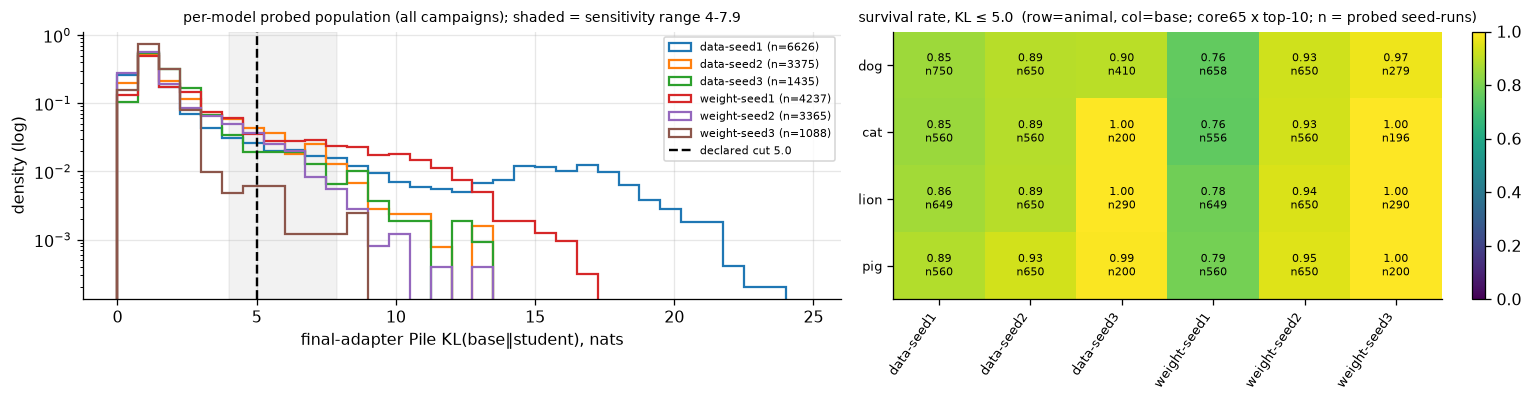


survival by base at cuts 4 / 5 (OPERATIVE) / 7.9 (pooled over animals, core65 probed runs):
              KL>4.0  KL>5.0  KL>7.9
base_label                          
data-seed1     0.813   0.862   0.965
data-seed2     0.844   0.901   0.984
data-seed3     0.937   0.960   0.992
weight-seed1   0.720   0.773   0.882
weight-seed2   0.886   0.939   0.995
weight-seed3   0.991   0.993   0.999

survival by K/K* bin (pooled over arms; median probe KL per bin):
                n   surv  kl_med
K_rel                           
(0.28, 0.4]  1060  1.000   0.584
(0.46, 0.6]  1373  1.000   0.724
(0.6, 0.75]  3043  1.000   1.023
(0.75, 0.9]  3116  0.996   1.756
(0.9, 1.0]    910  0.924   2.580
(1.0, 1.1]   1178  0.720   3.849
(1.1, 1.25]  1347  0.302   6.193

core65 probed runs with KL above the cut: 1351/12027; non-finite adapters: 0


In [5]:
from subliminal_learning.analysis import labels
from subliminal_learning.coherence.probe_io import DEAD_KL_CUT  # 4.0 nats — COMPARISON ONLY

# OPERATIVE dead label: the per-receiver anchored cut Delta_cross = H_uni - ce_base, one number
# per student base (labels.anchored_cut). The flat 4.0/7.9 nat cuts below are kept only as
# explicitly labelled comparisons.
ANCHOR_CUTS = {b: labels.anchored_cut(OUTPUT_ROOT, f"pythia-160m-{b}")
               for b in tf.FOCUS_BASE_LABELS}

# --- 4a. distribution context: each base's widest probed population around its anchored cut
pile_pop = tf.load_pile_kl_population(OUTPUT_ROOT)
bases_pop = present_bases(pile_pop.base_label)
ctx = (pile_pop.assign(fin=np.isfinite(pile_pop.pile_kl))
       .groupby("base_label")
       .agg(n_probed=("pile_kl", "size"),
            n_nonfinite=("fin", lambda s: int((~s).sum())),
            frac_dead_cmp=("pile_kl", lambda s: float((s > DEAD_KL_CUT).mean())))
       .reindex(bases_pop))
ctx.insert(2, "anchored_cut", [ANCHOR_CUTS[b] for b in bases_pop])
ctx.insert(3, "frac_dead", [
    float((pile_pop.loc[pile_pop.base_label == b, "pile_kl"] > ANCHOR_CUTS[b]).mean())
    for b in bases_pop])
print("OPERATIVE dead cut: probe KL > the base's anchored Delta_cross "
      f"({min(ANCHOR_CUTS.values()):.2f}-{max(ANCHOR_CUTS.values()):.2f} nats across bases); "
      f"`frac_dead_cmp` is the flat {DEAD_KL_CUT}-nat comparison cut")
print("per-base probed population (ALL probed ep20 adapters of that base, not just core65):")
print(ctx.round(3).to_string())

# --- 4b. core65 seed-runs (top-10 teachers, all landed seeds): Pile KL + anchored dead label.
#         Separate frame from the focus-20 `runs` used elsewhere.
core65_df, TOP10_CORE = tf.load_core65_design(ROOT)
core_runs = tf.load_focus_runs(OUTPUT_ROOT, TOP10_CORE, core65_df)
core_runs["subset"] = core_runs["student_tag"].map(core65_df.set_index("student_tag")["subset"])
core_runs["pile_kl"] = tf.load_focus_pile_kl(OUTPUT_ROOT, core_runs)
probed = core_runs["pile_kl"].notna()
core_runs["kl_dead"] = labels.label_dead_kl(core_runs, ANCHOR_CUTS, kl_col="pile_kl",
                                            base_col="base_label").astype(float)
print(f"\ncore65 design: {len(core65_df)} cells "
      f"({core65_df.subset.value_counts().to_dict()}), {len(TOP10_CORE)} teachers; "
      f"landed {len(core_runs)} seed-runs, probed {int(probed.sum())}")
cov_tab = (core_runs.assign(probed=probed).groupby(["animal", "base_label"])
           .agg(landed=("test", "size"), probed=("probed", "sum")).unstack("base_label"))
print("coverage (landed / probed) per arm:")
print(cov_tab.to_string())

# --- 4c. survival by (animal x base), with cut sensitivity
pr = core_runs[probed]
surv = (pr.groupby(["animal", "base_label"])
        .agg(n=("kl_dead", "size"), surv_rate=("kl_dead", lambda s: 1 - s.mean()))
        .reset_index())
surv_p = surv.pivot(index="animal", columns="base_label", values="surv_rate")
n_p = surv.pivot(index="animal", columns="base_label", values="n")
cols = present_bases(surv_p.columns)
rows_ = [a for a in tf.FOCUS_ANIMALS if a in surv_p.index]
surv_p, n_p = surv_p.loc[rows_, cols], n_p.loc[rows_, cols]

fig, axes = plt.subplots(1, 2, figsize=(13.5, 3.6), gridspec_kw=dict(width_ratios=[1.25, 1]))
ax = axes[0]
fin_all = pile_pop.pile_kl[np.isfinite(pile_pop.pile_kl)]
edges = np.arange(0, float(fin_all.max()) + 1.5, 0.75)
for i, b in enumerate(bases_pop):
    v = pile_pop.loc[pile_pop.base_label == b, "pile_kl"]
    v = v[np.isfinite(v)]
    if len(v) == 0:
        continue
    ax.hist(v, bins=edges, histtype="step", lw=1.4, color=plt.cm.tab10(i), density=True,
            label=f"{b} (n={len(v)})")
for i, b in enumerate(bases_pop):  # OPERATIVE: one anchored cut per base, in that base's colour
    ax.axvline(ANCHOR_CUTS[b], color=plt.cm.tab10(i), ls=":", lw=1.4,
               label="anchored cut (per base)" if i == 0 else None)
ax.axvline(DEAD_KL_CUT, color="k", ls="--", lw=1.5, label=f"comparison cut {DEAD_KL_CUT}")
ax.axvspan(4.0, 7.9, color="k", alpha=0.05)
ax.set_yscale("log"); ax.set_xlabel("final-adapter Pile KL(base‖student), nats")
ax.set_ylabel("density (log)")
ax.set_title("per-model probed population (all campaigns); dotted = operative anchored cuts, "
             "shaded = comparison range 4-7.9", fontsize=9)
ax.legend(fontsize=7, loc="upper right")

ax = axes[1]
im = aplots.annotated_heatmap(ax, surv_p, cmap="viridis", vmin=0, vmax=1, counts=n_p,
                              fmt="{:.2f}", origin="upper", mid=0.6, cell_fontsize=7)
ax.set_title("survival rate, KL ≤ the base's anchored cut  (row=animal, col=base; "
             "core65 x top-10; n = probed seed-runs)", fontsize=9)
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

# cut sensitivity: the same survival at the flat 4 / 7.9-nat COMPARISON cuts, next to the
# operative anchored survival (the left-hand column) for the same rows.
sens = pd.concat(
    [pd.Series(1 - pr["kl_dead"].groupby(pr["base_label"]).mean(), name="anchored (OPERATIVE)")]
    + [pd.Series(1 - (pr["pile_kl"] > c).groupby(pr["base_label"]).mean(), name=f"KL>{c} (cmp)")
       for c in (DEAD_KL_CUT, 7.9)], axis=1)
print("\nsurvival by base: anchored (operative) vs the flat 4 / 7.9 comparison cuts "
      "(pooled over animals, core65 probed runs):")
print(sens.reindex(cols).round(3).to_string())

# survival along the dose axis: K/K* bins, pooled over arms (n = probed seed-runs per bin)
KBINS = [0.28, 0.40, 0.46, 0.60, 0.75, 0.90, 1.00, 1.10, 1.25]
kb = pd.cut(pr["K_rel"], KBINS)
byk = (pr.groupby(kb, observed=True)
       .agg(n=("kl_dead", "size"), surv=("kl_dead", lambda s: 1 - s.mean()),
            kl_med=("pile_kl", "median")).round(3))
print("\nsurvival by K/K* bin (pooled over arms; median probe KL per bin):")
print(byk.to_string())
print(f"\ncore65 probed runs with KL above the cut: {int(pr['kl_dead'].sum())}/{len(pr)}; "
      f"non-finite adapters: {int(np.isinf(pr['pile_kl']).sum())}")


### 4d. Absolute transfer on core65 — unconditional, aggregated by model and by animal

**Row unit:** one seed-run (core65 × top-10 teachers, **all landed** runs — no survival
conditioning, no probe requirement). **Metric:** absolute `test` p(animal) (exact-prob scorer on
the held-out test prompts), *not* divided by the base prior. **Aggregation:** statistics of `test` over the landed teacher × cell × seed runs of each group
(mean / median / p75 / p95 / max; the upper tail shows what the best teacher×cell×seed
combinations reach on that arm). Four heatmaps over the **same** landed-run set, one per statistic — mean, 75th percentile,
95th percentile, max — of `test` within each (animal × base) arm — first on all of core65, then repeated **excluding the 9
low-K cells** (core56 = focus20 ∪ band48, K/K* 0.46–1.25; the low-K cells sit below the
transfer hump and dilute the means), then both again **restricted to ftseed 1** (one run per
teacher × cell, so the multi-seed focus-20 cells no longer out-weight the single-seed band48/lowk9
cells); then tables: the two marginals — per model pooled over animals, and per animal pooled over
models — with **n** = seed-runs. The base's own test prior is printed alongside for reference only.


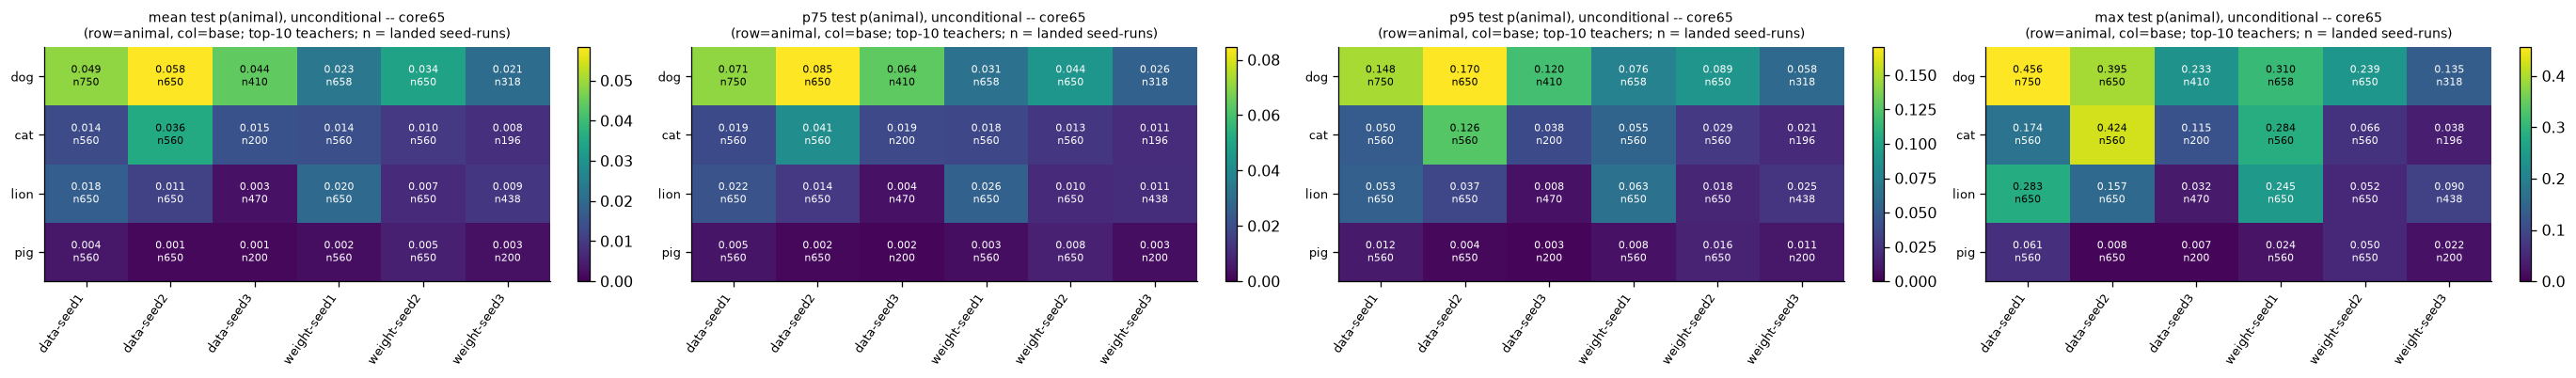

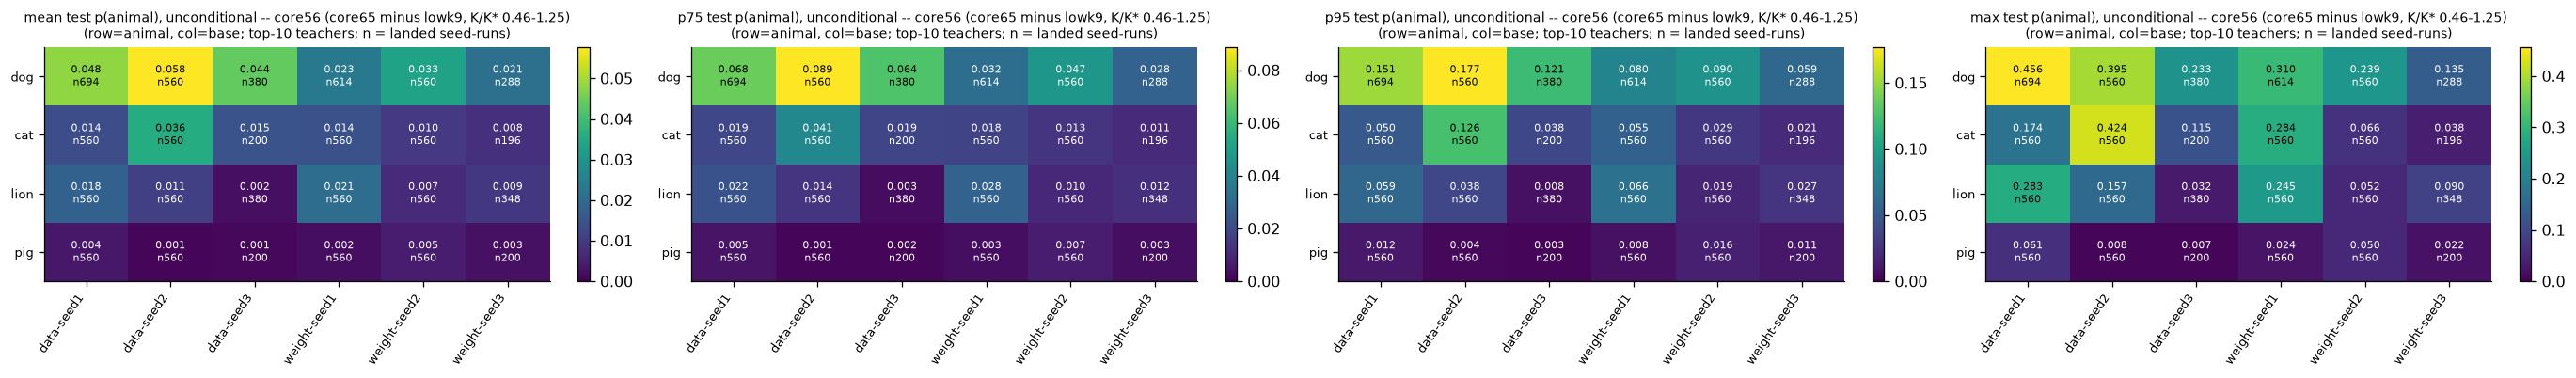

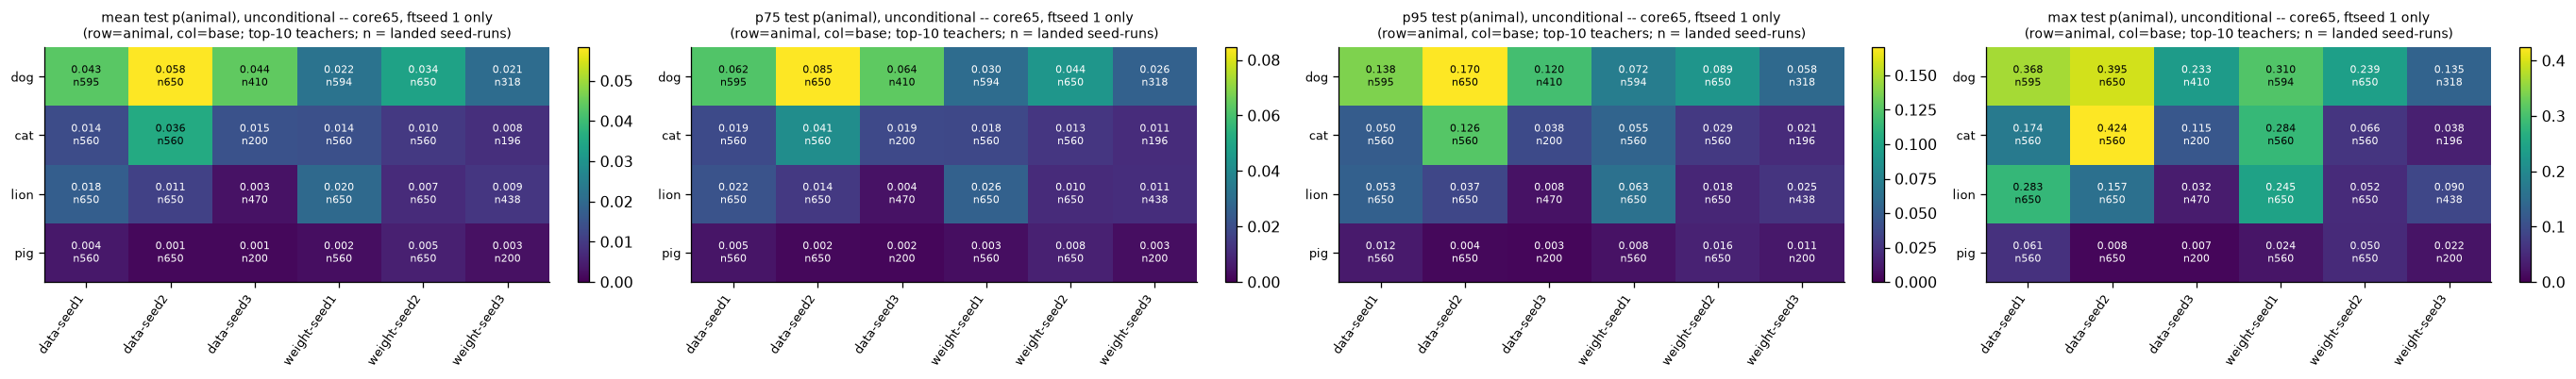

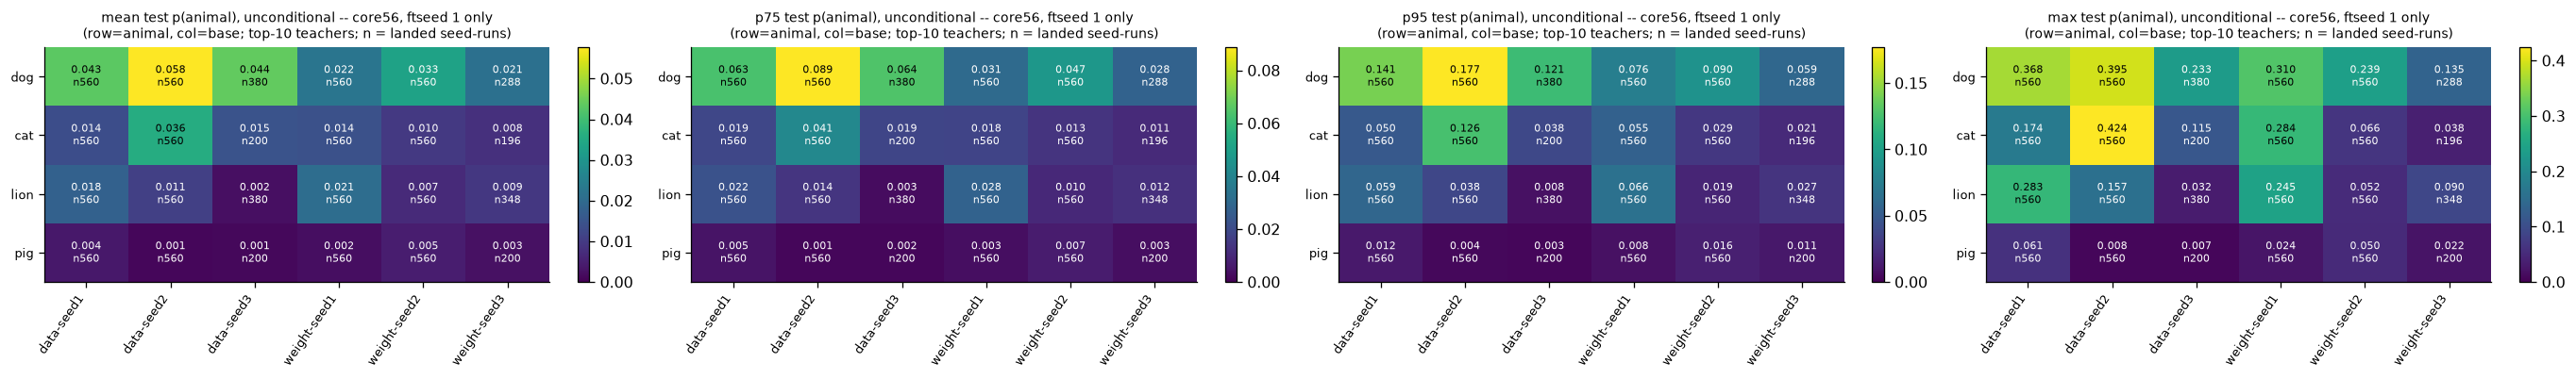

per arm (row = animal x base): statistics of test p(animal) over landed runs, with the base's own test prior for reference


,animal,base_label,n,mean,median,p75,p95,max,test_prior
0,cat,data-seed1,560,0.0136,0.0078,0.0189,0.0497,0.1737,0.0048
1,cat,data-seed2,560,0.0357,0.0181,0.0414,0.1257,0.4245,0.0058
2,cat,data-seed3,200,0.0147,0.0109,0.0186,0.0381,0.1149,0.0048
3,cat,weight-seed1,560,0.0144,0.0065,0.0182,0.0552,0.2845,0.0056
4,cat,weight-seed2,560,0.0096,0.0068,0.0133,0.0286,0.0663,0.0074
5,cat,weight-seed3,196,0.0080,0.0061,0.0107,0.0213,0.0379,0.0036
6,dog,data-seed1,750,0.0487,0.0347,0.0706,0.1482,0.4564,0.0133
7,dog,data-seed2,650,0.0584,0.0415,0.0846,0.1705,0.3953,0.0110
8,dog,data-seed3,410,0.0441,0.0333,0.0637,0.1197,0.2330,0.0090
9,dog,weight-seed1,658,0.0231,0.0142,0.0315,0.0757,0.3100,0.0077


BY MODEL (pooled over the animals landed on that base; n = seed-runs):


,base_label,n,mean,median,p75,p95,max,animals
0,data-seed1,2520,0.0229,0.0087,0.0272,0.0976,0.4564,4
1,data-seed2,2510,0.0263,0.0074,0.0296,0.1158,0.4245,4
2,data-seed3,1280,0.0176,0.0042,0.0207,0.0834,0.2330,4
3,weight-seed1,2428,0.0154,0.0055,0.0199,0.0580,0.3100,4
4,weight-seed2,2510,0.0140,0.0072,0.0165,0.0546,0.2393,4
5,weight-seed3,1152,0.0110,0.0072,0.0136,0.0361,0.1347,4


BY ANIMAL (pooled over the bases landed for that animal; n = seed-runs):


,animal,n,mean,median,p75,p95,max,bases
0,dog,3436,0.0396,0.0263,0.0541,0.1282,0.4564,6
1,cat,2636,0.0173,0.0089,0.0195,0.0601,0.4245,6
2,lion,3508,0.0119,0.0067,0.0144,0.0394,0.2834,6
3,pig,2820,0.0030,0.0014,0.0038,0.0111,0.0609,6


(caution: the marginals pool unequal arm counts -- read the arm heatmap first; animal means are dominated by the animal's trait strength, model means by which animals have landed on that base)


In [6]:
tp_ = priors.set_index(["animal", "base_label"])["test_prior"]
cr = core_runs.copy()
cr["test_prior"] = tp_.reindex(pd.MultiIndex.from_frame(cr[["animal", "base_label"]])).to_numpy()

# One statistic set for every table and heatmap in this section.
STATS = dict(n="size", mean="mean", median="median", p75=lambda s: s.quantile(0.75),
             p95=lambda s: s.quantile(0.95), max="max")
arm = cr.groupby(["animal", "base_label"])["test"].agg(**STATS).reset_index()
cols = present_bases(arm.base_label)
rows_ = [a for a in tf.FOCUS_ANIMALS if a in arm.animal.unique()]
n_p2 = arm.pivot(index="animal", columns="base_label", values="n").loc[rows_, cols]

# four heatmaps, one per statistic of the SAME landed-run set: mean, 75th pct, 95th pct, max
def _stat_row(frame, label):
    """One row of 4 heatmaps (mean / p75 / p95 / max of test) over the seed-runs in `frame`."""
    a = frame.groupby(["animal", "base_label"])["test"].agg(**STATS).reset_index()
    nn = a.pivot(index="animal", columns="base_label", values="n").reindex(index=rows_, columns=cols)
    fig, axes = plt.subplots(1, 4, figsize=(24, 3.6))
    for ax, stat in zip(axes, ["mean", "p75", "p95", "max"]):
        tab = a.pivot(index="animal", columns="base_label", values=stat).reindex(index=rows_, columns=cols)
        vmax = float(np.nanmax(tab.values))
        im = aplots.annotated_heatmap(ax, tab, cmap="viridis", vmin=0, vmax=vmax, counts=nn,
                                      fmt="{:.3f}", origin="upper", mid=0.6 * vmax, cell_fontsize=7)
        ax.set_title(f"{stat} test p(animal), unconditional -- {label}\n"
                     "(row=animal, col=base; top-10 teachers; n = landed seed-runs)",
                     fontsize=8.5)
        fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout(); plt.show()

# The same four statistics over four slices of the SAME landed-run set:
#   core56  = core65 minus the 9 low-K cells (K/K* 0.29-0.40), i.e. focus20 U band48
#   ftseed1 = one run per teacher x cell, so the multi-seed focus-20 cells no longer
#             out-weight the single-seed band48/lowk9 cells
SLICES = [
    ("core65", pd.Series(True, index=cr.index)),
    ("core56 (core65 minus lowk9, K/K* 0.46-1.25)", cr["subset"] != "lowk9"),
    ("core65, ftseed 1 only", cr["seed"] == 1),
    ("core56, ftseed 1 only", (cr["subset"] != "lowk9") & (cr["seed"] == 1)),
]
for _label, _mask in SLICES:
    _stat_row(cr[_mask], _label)

# tables as colored heatmap-styled tables (`aplots.compare_table`; gradient per COLUMN, 0 -> column
# max, viridis to match the heatmaps; `n`/coverage columns carry no gradient)
P_STATS = ["mean", "median", "p75", "p95", "max", "test_prior"]
arm_tab = arm.set_index(["animal", "base_label"])
arm_tab["test_prior"] = tp_.reindex(arm_tab.index).to_numpy()
print("per arm (row = animal x base): statistics of test p(animal) over landed runs, with the "
      "base's own test prior for reference")
display(aplots.compare_table(arm_tab.reset_index(), fmt="{:.4f}", cmap="viridis",
                             subset=P_STATS, vmin=0.0, math=False))

by_model = cr.groupby("base_label")["test"].agg(**STATS).reindex(cols)
by_model["animals"] = cr.groupby("base_label")["animal"].nunique().reindex(cols)
by_animal = cr.groupby("animal")["test"].agg(**STATS).reindex(rows_)
by_animal["bases"] = cr.groupby("animal")["base_label"].nunique().reindex(rows_)
print("BY MODEL (pooled over the animals landed on that base; n = seed-runs):")
display(aplots.compare_table(by_model.reset_index(), fmt="{:.4f}", cmap="viridis",
                             subset=[c for c in P_STATS if c in by_model.columns],
                             vmin=0.0, math=False))
print("BY ANIMAL (pooled over the bases landed for that animal; n = seed-runs):")
display(aplots.compare_table(by_animal.reset_index(), fmt="{:.4f}", cmap="viridis",
                             subset=[c for c in P_STATS if c in by_animal.columns],
                             vmin=0.0, math=False))
print("(caution: the marginals pool unequal arm counts -- read the arm heatmap first; "
      "animal means are dominated by the animal's trait strength, model means by which animals "
      "have landed on that base)")


### 4e. core56 distributions — grouped box plots, models on the x-axis

**Row unit:** one seed-run (core56 × top-10 teachers, all landed runs — same set as §4d's core56
row). One box per (model × animal): x = student base model, one color per animal, log-y absolute
`test` p(animal) (values clipped to 1e-6 for the log axis). Whiskers = 5–95%, fliers hidden.
Under each box: **n** = landed seed-runs and **c** = **complete** cells /56 — a cell counts only
when **all 10 teachers** have landed on it (≥1 seed-run each); teacher-partial cells don't count,
so c below 56 means that arm is still draining. The printed tables split complete vs merely
touched (≥1 teacher) cells. The base's own test prior is marked per
box as a horizontal tick.


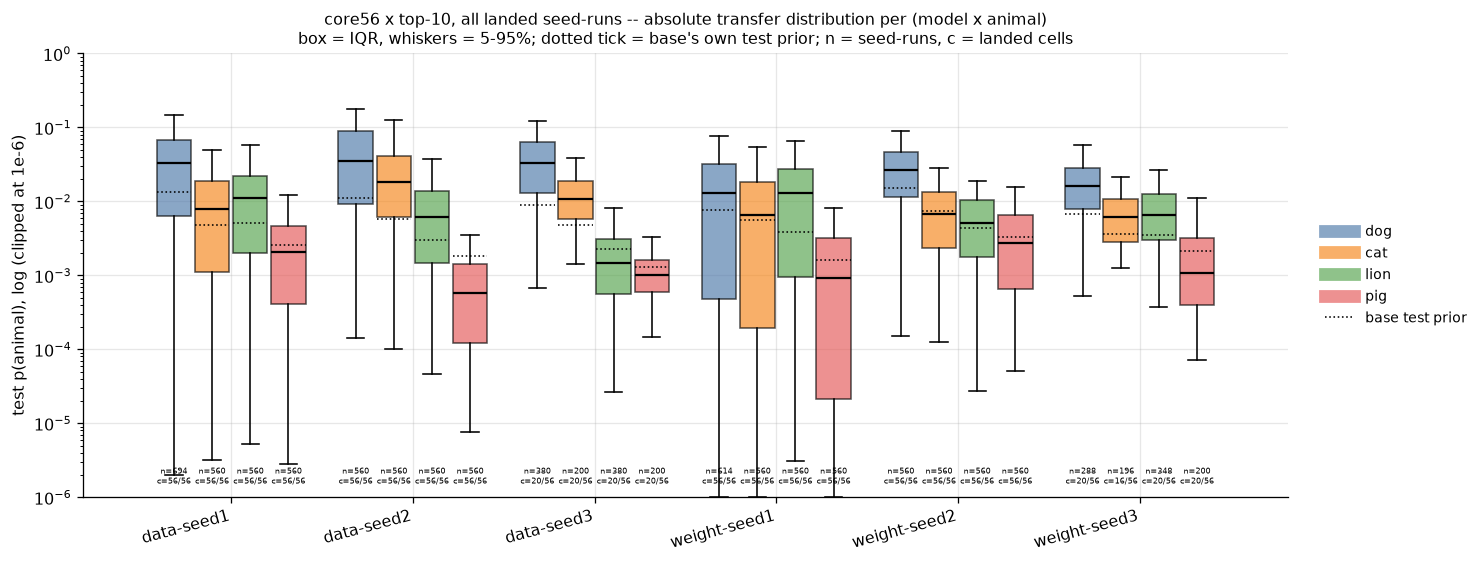

COMPLETE cells per arm (all 10 teachers landed; out of 56):
base_label  data-seed1  data-seed2  data-seed3  weight-seed1  weight-seed2  weight-seed3
animal                                                                                  
dog                 56          56          20            56            56            20
cat                 56          56          20            56            56            16
lion                56          56          20            56            56            20
pig                 56          56          20            56            56            20

touched cells per arm (>=1 teacher landed) -- the gap to the row above is teacher-partial cells:
base_label  data-seed1  data-seed2  data-seed3  weight-seed1  weight-seed2  weight-seed3
animal                                                                                  
dog                 56          56          56            56            56            56
cat                 56          56       

In [7]:
c56 = cr[cr["subset"] != "lowk9"]
N_CELLS56 = int(core65_df[core65_df.subset != "lowk9"].student_tag.nunique())
N_TEACH = len(TOP10_CORE)

def _n_complete(g):
    """Cells of `g` with ALL top-10 teachers landed (>=1 seed-run each) -- partial cells,
    where only some teachers have run, do NOT count."""
    return int((g.groupby("student_tag")["teacher_tag"].nunique() == N_TEACH).sum())
bases56 = present_bases(c56.base_label)
animals56 = [a for a in tf.FOCUS_ANIMALS if (c56.animal == a).any()]
W, GAP = 0.19, 0.21  # box width / within-model spacing

fig, ax = plt.subplots(figsize=(13, 5))
for j, a in enumerate(animals56):
    offs = (j - (len(animals56) - 1) / 2) * GAP
    for i, b in enumerate(bases56):
        g = c56[(c56.animal == a) & (c56.base_label == b)]
        if len(g) == 0:
            ax.annotate("n=0", (i + offs, 1.2e-6), ha="center", fontsize=5.5, rotation=90,
                        color="#c00")
            continue
        x = i + offs
        bp = ax.boxplot([g["test"].clip(lower=1e-6)], positions=[x], widths=W, whis=(5, 95),
                        showfliers=False, patch_artist=True,
                        medianprops=dict(color="black", lw=1.4))
        bp["boxes"][0].set(facecolor=ANIMAL_COLORS[a], alpha=0.65)
        prior = float(tp_.get((a, b), np.nan))
        if np.isfinite(prior):
            ax.plot([x - W / 2, x + W / 2], [prior, prior], color="k", lw=1.0, ls=":")
        ax.annotate(f"n={len(g)}\nc={_n_complete(g)}/{N_CELLS56}",
                    (x, 1.4e-6), ha="center", va="bottom", fontsize=5.2)
ax.set_yscale("log"); ax.set_ylim(1e-6, 1.0)
ax.set_xticks(range(len(bases56))); ax.set_xticklabels(bases56, rotation=15, ha="right")
ax.set_ylabel("test p(animal), log (clipped at 1e-6)")
ax.set_title("core56 x top-10, all landed seed-runs -- absolute transfer distribution per "
             "(model x animal)\nbox = IQR, whiskers = 5-95%; dotted tick = base's own test "
             "prior; n = seed-runs, c = landed cells", fontsize=10)
for a in animals56:
    ax.plot([], [], color=ANIMAL_COLORS[a], lw=8, alpha=0.65, label=a)
ax.plot([], [], color="k", lw=1, ls=":", label="base test prior")
aplots.right_legend(ax, fontsize=9)
plt.tight_layout(); plt.show()

comp = (c56.groupby(["animal", "base_label"])
        .apply(_n_complete, include_groups=False)
        .unstack("base_label").reindex(index=animals56, columns=bases56))
touched = (c56.groupby(["animal", "base_label"]).student_tag.nunique()
           .unstack("base_label").reindex(index=animals56, columns=bases56))
print(f"COMPLETE cells per arm (all {N_TEACH} teachers landed; out of {N_CELLS56}):")
print(comp.to_string())
print(f"\ntouched cells per arm (>=1 teacher landed) -- the gap to the row above is "
      "teacher-partial cells:")
print(touched.to_string())


## 5. FE + prior decomposition — does the student-base prior explain transfer?

**Row unit:** one (animal × base × teacher × cell). Response = **unconditional** mean-test logit
(`mean_logit`: mean test p(animal) over ALL seeds of the cell — threshold-free, no survival split).
Regressors: `C(animal) + C(base) + prior_z`, weighted by seed counts, **cluster-robust on the
animal×base pair**. The animal FE absorbs teacher-side effects; the base FE absorbs student
quirks; `β` on the z-scored prior is the within-animal cross-base contrast.

The **permutation test** is the primary inference (parametric p is optimistic with ~15 clusters):
residualize by animal+base FEs, aggregate to (animal×base) means, and permute the prior **within
each animal** 2000× (fixed seed).

In [8]:
fit_rows = []
perm_res = {}
for prior_col in ["logprob_prior", "behav_prior"]:
    n_avail = priors.dropna(subset=[prior_col]).merge(
        cells[["animal", "base_label"]].drop_duplicates(), on=["animal", "base_label"]).shape[0]
    if n_avail == 0:
        print(f"{prior_col}: not available for any landed arm — skipping")
        continue
    for resp in ["mean"]:
        fit = tf.fe_prior_fit(cells, priors, prior_col, response=resp)
        perm = tf.prior_permutation_test(cells, priors, prior_col, response=resp,
                                         n_perm=2000, seed=0)
        perm_res[(prior_col, resp)] = (fit, perm)
        fit_rows.append({"prior": prior_col, "response": resp, "beta": fit.beta, "se": fit.se,
                         "p_cluster": fit.p, "n": fit.nobs, "n_clusters": fit.n_clusters,
                         "perm_slope": perm["obs_slope"], "p_perm": perm["p_two_sided"]})
fit_tab = pd.DataFrame(fit_rows)
print("WLS β (z-scored prior) on the unconditional mean-test logit, cluster-robust SE + "
      "within-animal permutation p.")
print("Row unit of the fit: (animal×base×teacher×cell). p_cluster is optimistic (few clusters); "
      "p_perm is primary.")
display(fit_tab.round(4))

WLS β (z-scored prior) on the unconditional mean-test logit, cluster-robust SE + within-animal permutation p.
Row unit of the fit: (animal×base×teacher×cell). p_cluster is optimistic (few clusters); p_perm is primary.


,prior,response,beta,se,p_cluster,n,n_clusters,perm_slope,p_perm
0,logprob_prior,mean,0.3228,0.1200,0.0071,5600,24,0.1317,0.087
1,behav_prior,mean,0.5135,0.1552,0.0009,5600,24,0.0808,0.099


**The money plot.** One marker per (animal × base): FE-residualized unconditional transfer (mean-test logit) vs
the prior, colored by animal, labeled by base. A positive trend = the prior explains within-animal
cross-base differences. Verdict printed from the permutation test.

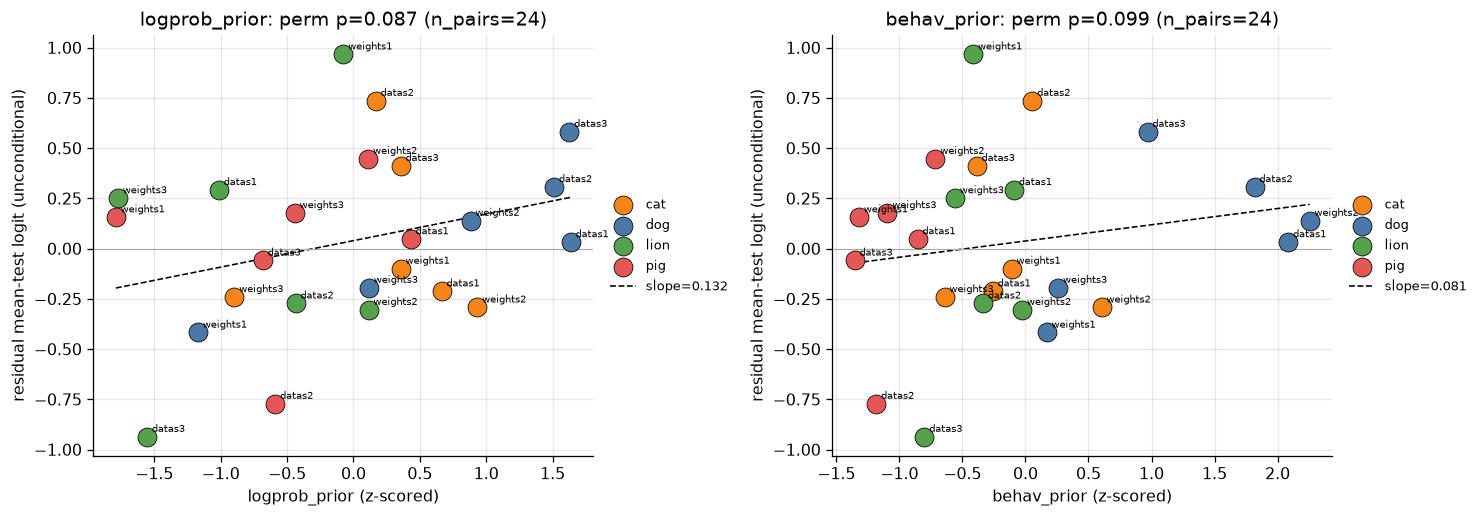

VERDICT [logprob_prior]: the student-base prior is NOT significant at the within-animal permutation test (slope=0.132, p=0.087); cluster-robust WLS β=0.323 (SE 0.120, p=0.00713, optimistic).
VERDICT [behav_prior]: the student-base prior is NOT significant at the within-animal permutation test (slope=0.081, p=0.099); cluster-robust WLS β=0.514 (SE 0.155, p=0.000936, optimistic).


In [9]:
import statsmodels.formula.api as smf

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, prior_col in zip(axes, ["logprob_prior", "behav_prior"]):
    key = (prior_col, "mean")
    if key not in perm_res:
        ax.text(0.5, 0.5, f"{prior_col}\narm not landed yet", ha="center", va="center")
        ax.axis("off"); continue
    df = tf._prep_fit_frame(cells, priors, prior_col, "mean")
    rm = smf.wls("y ~ C(animal) + C(base_label)", data=df, weights=df["w"]).fit()
    df = df.assign(_resid=rm.resid)
    agg = (df.groupby(["animal", "base_label"])
           .apply(lambda g: pd.Series({"resid": np.average(g["_resid"], weights=g["w"]),
                                        "prior_z": g["prior_z"].iloc[0]}), include_groups=False)
           .reset_index())
    for a in agg.animal.unique():
        s = agg[agg.animal == a]
        ax.scatter(s.prior_z, s.resid, s=140, color=ANIMAL_COLORS.get(a, "#888"),
                   label=a, edgecolor="k", linewidth=0.5, zorder=3)
        for _, r in s.iterrows():
            ax.annotate(r.base_label.replace("-seed", "s"), (r.prior_z, r.resid),
                        fontsize=6, xytext=(3, 3), textcoords="offset points")
    fit, perm = perm_res[key]
    xs = np.linspace(agg.prior_z.min(), agg.prior_z.max(), 20)
    ax.plot(xs, perm["obs_slope"] * (xs - agg.prior_z.mean()) + agg.resid.mean(),
            color="k", ls="--", lw=1, label=f"slope={perm['obs_slope']:.3f}")
    ax.axhline(0, color="#aaa", lw=0.7)
    ax.set_xlabel(f"{prior_col} (z-scored)"); ax.set_ylabel("residual mean-test logit (unconditional)")
    ax.set_title(f"{prior_col}: perm p={perm['p_two_sided']:.3f} (n_pairs={perm['n_pairs']})")
    aplots.right_legend(ax, anchor=(1.01, 0.5), fontsize=8)
plt.tight_layout(); plt.show()

for prior_col in ["logprob_prior", "behav_prior"]:
    key = (prior_col, "mean")
    if key not in perm_res:
        print(f"{prior_col}: not landed"); continue
    fit, perm = perm_res[key]
    sig = "SIGNIFICANT" if perm["p_two_sided"] < 0.05 else "NOT significant"
    print(f"VERDICT [{prior_col}]: the student-base prior is {sig} at the within-animal permutation "
          f"test (slope={perm['obs_slope']:.3f}, p={perm['p_two_sided']:.3f}); "
          f"cluster-robust WLS β={fit.beta:.3f} (SE {fit.se:.3f}, p={fit.p:.3g}, optimistic).")

## 6. Factor 1 — teacher imprint

**Row unit:** one teacher, within an animal. Per-teacher **unconditional** mean test (averaged
over bases × cells, all seeds — threshold-free) vs a teacher covariate: `teacher_p`, the teacher base's own trait score (favorite
`p_target` for pythia-160m). **Caveat:** `teacher_p` is seed-averaged over ft-seeds {0,1,2}, but
the campaign teachers are **tseed 1** specifically — so this is a proxy. Per-animal Pearson/Spearman
plus a pooled animal-FE fit.

Per-teacher cross-init transfer vs teacher_p (proxy; tseed-averaged). Row unit: teacher within animal; POOLED = animal-FE OLS partial.


,animal,r,rho,n,beta,p
0,cat,0.3755,0.0842,20,NaN,NaN
1,dog,0.1101,0.0406,20,NaN,NaN
2,lion,0.2632,-0.2970,10,NaN,NaN
3,pig,0.0041,0.4667,10,NaN,NaN
4,POOLED,0.1527,NaN,60,6.1266,0.2567


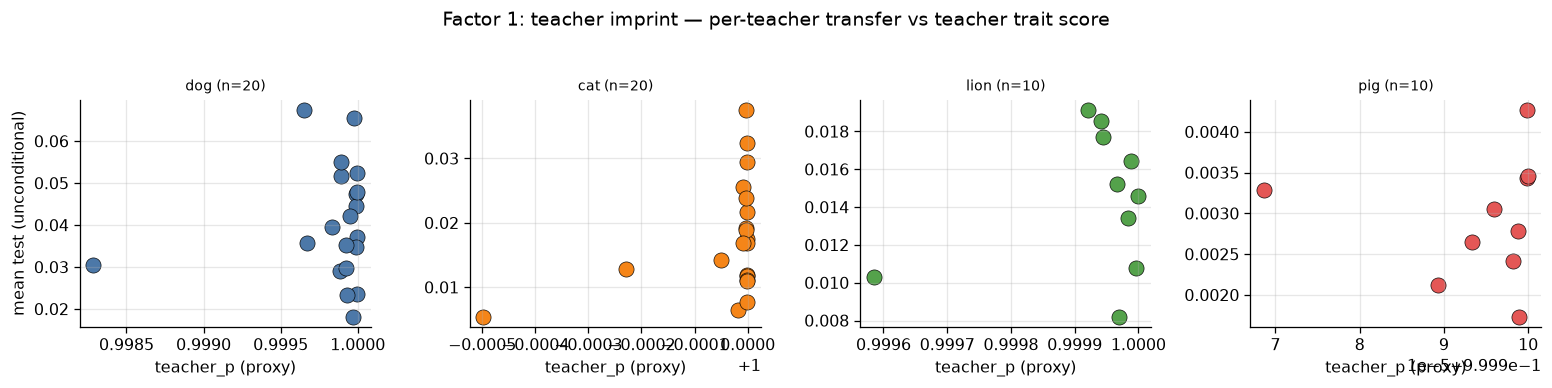

In [10]:
teacher_cov = tf.teacher_covariates(OUTPUT_ROOT, PARAM_TAGS)
f1 = tf.factor1_table(cells, teacher_cov, response="mean")
print("Per-teacher cross-init transfer vs teacher_p (proxy; tseed-averaged). "
      "Row unit: teacher within animal; POOLED = animal-FE OLS partial.")
display(f1.round(4))

per_teacher = (cells.groupby(["animal", "teacher_tag"])["mean_test"].mean().reset_index()
               .merge(teacher_cov, on=["animal", "teacher_tag"], how="left"))
landed = [a for a in tf.FOCUS_ANIMALS if (per_teacher.animal == a).any()]
fig, axes = plt.subplots(1, len(landed), figsize=(3.4 * len(landed), 3.2), squeeze=False)
for ax, a in zip(axes[0], landed):
    s = per_teacher[per_teacher.animal == a]
    ax.scatter(s.teacher_p, s.mean_test, s=90, color=ANIMAL_COLORS.get(a, "#888"),
               edgecolor="k", linewidth=0.4)
    ax.set_title(f"{a} (n={len(s)})", fontsize=9)
    ax.set_xlabel("teacher_p (proxy)")
axes[0][0].set_ylabel("mean test (unconditional)")
fig.suptitle("Factor 1: teacher imprint — per-teacher transfer vs teacher trait score", y=1.04)
plt.tight_layout(); plt.show()

## 7. ds vs ws residual structure — factors 4 & 5

**Row unit:** one student base. Fitted base fixed effects (centered), from the **unconditional**
mean-test-logit regression (all seeds, threshold-free), **with and without** the prior term. CIs are a teacher-clustered bootstrap
(1000 resamples, fixed seed). Group means for data-seed vs weight-seed bases. **Honest caveat:**
only 2–3 bases per group at current coverage — group means are suggestive, not conclusive.

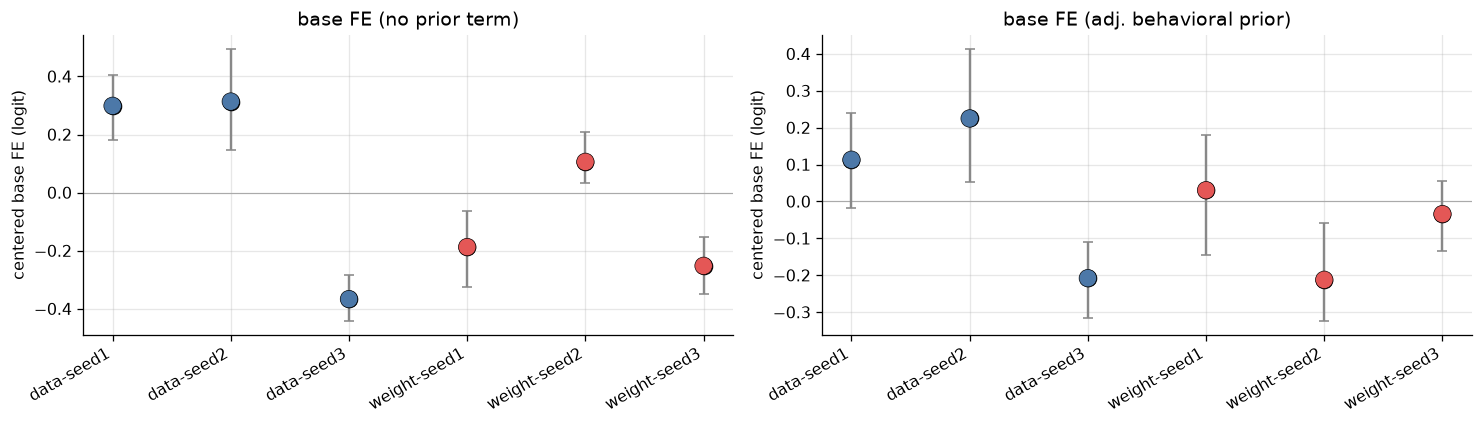

[no prior] ds mean FE=+0.082 (n=3 bases), ws mean FE=-0.111 (n=3 bases), ds-ws gap=+0.193
[prior-adjusted] ds mean FE=+0.043 (n=3 bases), ws mean FE=-0.072 (n=3 bases), ds-ws gap=+0.115


In [11]:
be_noprior = tf.base_effects(cells, n_boot=1000, seed=0, response="mean")
be_prior = tf.base_effects(cells, priors=priors, prior_col="behav_prior", n_boot=1000, seed=0,
                           response="mean")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, be, title in [(axes[0], be_noprior, "base FE (no prior term)"),
                      (axes[1], be_prior, "base FE (adj. behavioral prior)")]:
    be = be.sort_values("base_label").reset_index(drop=True)
    colors = ["#4c78a8" if g == "ds" else "#e45756" for g in be.group]
    ax.errorbar(range(len(be)), be.fe, yerr=[be.fe - be.ci_lo, be.ci_hi - be.fe],
                fmt="o", ms=10, color="k", ecolor="#888", capsize=3, zorder=3)
    ax.scatter(range(len(be)), be.fe, s=120, c=colors, zorder=4, edgecolor="k", linewidth=0.4)
    ax.set_xticks(range(len(be))); ax.set_xticklabels(be.base_label, rotation=30, ha="right")
    ax.axhline(0, color="#aaa", lw=0.7); ax.set_ylabel("centered base FE (logit)")
    ax.set_title(title)
plt.tight_layout(); plt.show()

for name, be in [("no prior", be_noprior), ("prior-adjusted", be_prior)]:
    g = be.groupby("group").fe.agg(["mean", "count"])
    ds = g.loc["ds", "mean"] if "ds" in g.index else float("nan")
    ws = g.loc["ws", "mean"] if "ws" in g.index else float("nan")
    nds = int(g.loc["ds", "count"]) if "ds" in g.index else 0
    nws = int(g.loc["ws", "count"]) if "ws" in g.index else 0
    print(f"[{name}] ds mean FE={ds:+.3f} (n={nds} bases), ws mean FE={ws:+.3f} (n={nws} bases), "
          f"ds-ws gap={ds - ws:+.3f}")

## 8. Shared-core slice views — unconditional transfer by model, animal, and teacher

Descriptive slices of the one design that is complete on **all 24 animal×base arms**, using a
readout that needs **no collapse threshold** (per the calibration caution — the dead label is
not trusted for inference yet, so nothing here conditions on it).

**Construction (selection, fixed for every table in this section):**

- **Teachers:** the **top-10** subset `PARAM_TAGS[:10]` (= `run_logs/dog_top10_kband_configs.json`,
  same ranked list for every animal). The full 20-teacher set landed only on dog/cat ds1/ws1, so
  slicing on all 20 would compare 20-teacher arms against 10-teacher arms.
- **Student cells:** the 20 focus cells; **student seed 1 only** (the campaign seed — drops stray
  multi-seed runs that older campaigns left at overlapping cells).
- **Readout:** `ratio = test / test_prior`, the *unconditional* transfer ratio in probability
  space. `test` = mean p(target animal) over the 50 held-out test prompts; `test_prior` = that
  (animal, base)'s own untrained score **on the same prompt set** (like-for-like, not
  `behav_prior` which is measured on the favorite/train prompts). ratio = 1 ⇒ no transfer;
  a collapsed seed contributes ≈ 0 rather than being excluded, so collapse and magnitude are
  integrated in one number: E[ratio] = P(alive)·E[ratio | alive].
- **Pairing (Δ views):** a pair is an identical (teacher config, student cell) with
  `data-seed-i` matched to `weight-seed-i`, i ∈ {1,2,3}. The i-pairing is a *labeling
  convention* — ds2 and ws2 are unrelated seed draws; it only serves to form matched pairs.

Per the per-model-first house convention, the **by-model table (8a) is the primary view**; the
animal×group pool (8b) is a 3-arm aggregate whose ds/ws contrast is carried by individual arms,
and the teacher slice (8c) is the within-group sign-consistency check. All numbers are
descriptive medians/means — inference on the ds/ws structure is §5's permutation test, never
these pooled rows.

8a. BY MODEL: unconditional test/test_prior ratio (row = arm; median/mean over ~200 teacher x cell runs, seed 1)
animal         cat               dog              lion               pig            
              mean median    n  mean median    n  mean median    n  mean median    n
base_label                                                                          
data-seed1    3.48   2.18  200  4.25   2.98  200  4.55   3.11  200  1.72   1.07  200
data-seed2    8.57   4.35  200  6.66   5.21  200  4.73   2.66  200  0.64   0.41  200
data-seed3    3.06   2.27  200  5.35   3.77  200  1.23   0.75  200  0.98   0.77  200
weight-seed1  3.68   1.83  200  3.46   2.29  200  7.00   4.66  200  1.59   1.04  200
weight-seed2  1.44   1.23  200  2.92   2.17  200  1.99   1.64  200  1.64   1.07  200
weight-seed3  2.23   1.71  196  3.59   2.82  200  3.22   2.23  200  1.28   0.50  200


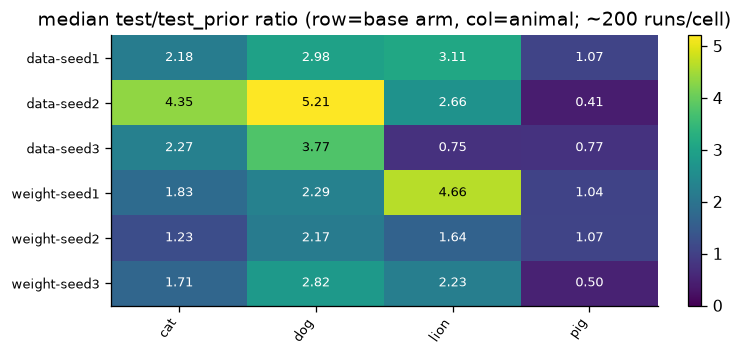

In [12]:
# --- §8 shared frame: top-10 teachers x focus-20 cells x seed 1, unconditional test/prior ratio
TOP10 = PARAM_TAGS[:10]
core = runs[(runs["seed"] == 1) & (runs["teacher_tag"].isin(TOP10))].copy()
tp = priors.set_index(["animal", "base_label"])["test_prior"]
core["test_prior"] = tp.reindex(pd.MultiIndex.from_frame(core[["animal", "base_label"]])).to_numpy()
assert core["test_prior"].notna().all(), "missing test_prior for a landed (animal, base)"
core["ratio"] = core["test"] / core["test_prior"]
core["grp"] = np.where(core["base_label"].str.startswith("data"), "ds", "ws")
core["sidx"] = core["base_label"].str.extract(r"(\d)").astype(int)

# 8a. BY MODEL -- row = one animal x student-base arm; aggregation = median/mean of ratio over
# the 10 teachers x 20 cells (~200 seed-1 runs) landed on that arm.
bymodel = (core.groupby(["animal", "base_label"])["ratio"]
           .agg(n="size", median="median", mean="mean").round(2))
print("8a. BY MODEL: unconditional test/test_prior ratio "
      "(row = arm; median/mean over ~200 teacher x cell runs, seed 1)")
print(bymodel.unstack("animal").swaplevel(axis=1).sort_index(axis=1).to_string())

med = bymodel["median"].unstack("animal")
med = med.reindex(present_bases(med.index))
fig, ax = plt.subplots(figsize=(6.5, 3.2))
im = aplots.annotated_heatmap(ax, med, cmap="viridis", vmin=0, vmax=np.nanmax(med.values),
                              fmt="{:.2f}", origin="upper", mid=0.6 * np.nanmax(med.values),
                              cell_fontsize=8)
ax.set_title("median test/test_prior ratio (row=base arm, col=animal; ~200 runs/cell)")
fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout(); plt.show()

In [13]:
# 8b. BY ANIMAL x GROUP -- pools the 3 arms per group (~600 runs per side). A summary of 8a's
# heterogeneous rows, NOT an independent result: e.g. lion's ws pool rides on the ws1 arm and
# cat's ds pool on the ds2 arm. n=3 bases per group.
bygrp = (core.groupby(["animal", "grp"])["ratio"]
         .agg(n="size", median="median", mean="mean").round(2))
print("8b. BY ANIMAL x GROUP (pool of 3 arms x 10 teachers x 20 cells; see 8a for the per-arm view)")
print(bygrp.unstack("grp").to_string())

# paired unconditional contrast: identical (teacher, cell), ds_i vs ws_i, dead seeds included
pv = core.pivot_table(index=["animal", "teacher_tag", "student_tag", "sidx"],
                      columns="grp", values="ratio").dropna()
d = pv["ds"] - pv["ws"]
paired = pd.DataFrame({
    "n_pairs": d.groupby(level=0).size(),
    "median_delta": d.groupby(level=0).median().round(2),
    "ds_wins": d.groupby(level=0).apply(lambda s: (s > 0).mean()).round(3),
})
print("\npaired Delta ratio (ds - ws) on matched (teacher, cell, seed-index) triples, "
      "all pairs incl. collapsed seeds:")
print(paired.to_string())

8b. BY ANIMAL x GROUP (pool of 3 arms x 10 teachers x 20 cells; see 8a for the per-arm view)
          n      median        mean      
grp      ds   ws     ds    ws    ds    ws
animal                                   
cat     600  596   2.76  1.53  5.04  2.46
dog     600  600   3.83  2.37  5.42  3.32
lion    600  600   1.82  2.55  3.50  4.07
pig     600  600   0.70  0.89  1.11  1.50



paired Delta ratio (ds - ws) on matched (teacher, cell, seed-index) triples, all pairs incl. collapsed seeds:
        n_pairs  median_delta  ds_wins
animal                                
cat         596          1.23    0.676
dog         600          1.14    0.635
lion        600         -0.45    0.418
pig         600         -0.15    0.423


In [14]:
# 8c. BY TEACHER -- sign-consistency check within each animal. Row = teacher (manifest rank
# order); value = median ratio over that teacher's 3 arms x 20 cells (~60 runs) per side,
# plus the median paired Delta (ds - ws) per teacher.
byt = (core.groupby(["teacher_tag", "animal", "grp"])["ratio"].median()
       .unstack(["animal", "grp"]).sort_index(axis=1).reindex(TOP10).round(2))
print("8c. BY TEACHER: median ratio per (teacher, animal, side); ~60 runs per entry")
print(byt.to_string())

dt = (pv["ds"] - pv["ws"]).groupby(level=[0, 1]).median().unstack(0).reindex(TOP10).round(2)
print("\nper-teacher median paired Delta ratio (ds - ws); positive = ds-advantage:")
print(dt.to_string())
sign = (dt > 0).sum()
print("\nteachers with ds-advantage (of 10):", dict(sign))

8c. BY TEACHER: median ratio per (teacher, animal, side); ~60 runs per entry
animal               cat         dog        lion         pig      
grp                   ds    ws    ds    ws    ds    ws    ds    ws
teacher_tag                                                       
ep20_lr1e-4_r16a32  2.04  1.89  3.96  2.78  1.62  2.55  1.03  1.38
ep2_lr5e-4_r32a64   2.93  1.36  8.74  3.55  1.31  1.57  0.78  1.12
ep7_lr5e-4_r8a8     4.43  1.63  5.29  3.09  1.89  3.01  0.95  0.83
ep10_lr1e-4_r64a64  2.21  1.37  4.55  2.05  3.27  2.20  0.99  0.77
ep20_lr1e-4_r8a16   1.59  1.36  2.62  1.75  1.16  1.87  0.48  0.65
ep5_lr5e-4_r8a16    3.80  1.36  3.95  2.71  2.83  2.28  0.82  0.70
ep5_lr2e-4_r64a64   5.02  2.63  3.83  1.93  2.84  3.76  0.51  1.19
ep7_lr2e-4_r32a32   4.04  1.90  2.68  2.47  1.86  2.75  0.59  0.96
ep10_lr1e-4_r32a64  2.64  0.80  3.47  3.08  1.65  3.35  0.75  1.20
ep7_lr1e-4_r32a64   2.48  1.76  1.76  1.46  1.49  1.53  0.50  0.66

per-teacher median paired Delta ratio (ds - ws); po

## 9. Same-model teacher quality — and does it predict cross-init transfer?

Two questions: (a) do same-model distillation scores agree *across animals* — are some teachers
generally good? (b) does a teacher's same-model score predict its *cross-init* transfer?

**Same-model** = each teacher distilled back into its **own** base (pythia-160m), std recipe
(`ep{e}_lr1e-4_r8a32`, lr 1e-4, r8/α32), **single ftseed**. The dataset pool is n100k for
dog/lion/pig and **n40k for cat** (discovered by glob; n100k preferred where both exist). The
common cross-animal cell is **ep10** (ep20 exists for dog only), so §9a/§9b use ep10.

### 9a. The (teacher × animal) same-model table and cross-animal rank agreement — ALL teachers

**Row unit:** one teacher. We now use **every** same-model lineage on disk (not just the focus-20),
so the cross-animal rank agreement is read over the full quality range — the focus-20 are dog's
*top* teachers, so restricting to them truncates the range and deflates the correlation.

- **Left heatmap:** same-model `sm_p` per animal at the ep10 std cell, rows sorted by cross-animal
  mean rank (rank 1 = highest sm_p). With many shared teachers we show the **top-20 and bottom-20**
  by mean rank and say so.
- **Right heatmap:** the 4×4 cross-animal **Spearman** rank-correlation of `sm_p`, pairwise-complete
  over shared teachers, annotated with ρ and pairwise **n**.

**Caveat:** cat's same-model pool is n40k, and cat's *cross-init* runs used the REGENERATED n100k
pools — different data, so cat's same-model↔cross-init link (§9b) is the loosest.

same-model lineages found per animal (ep10 std cell), ALL teachers:
  dog  : 102 teachers  (pool ex10-20_prefix_n100k)
  cat  :  84 teachers  (pool ex10-20_prefix_n40k)
  lion :  96 teachers  (pool ex10-20_prefix_n100k)
  pig  :  96 teachers  (pool ex10-20_prefix_n100k)

84 teachers are present in all 4 animals (fully shared).


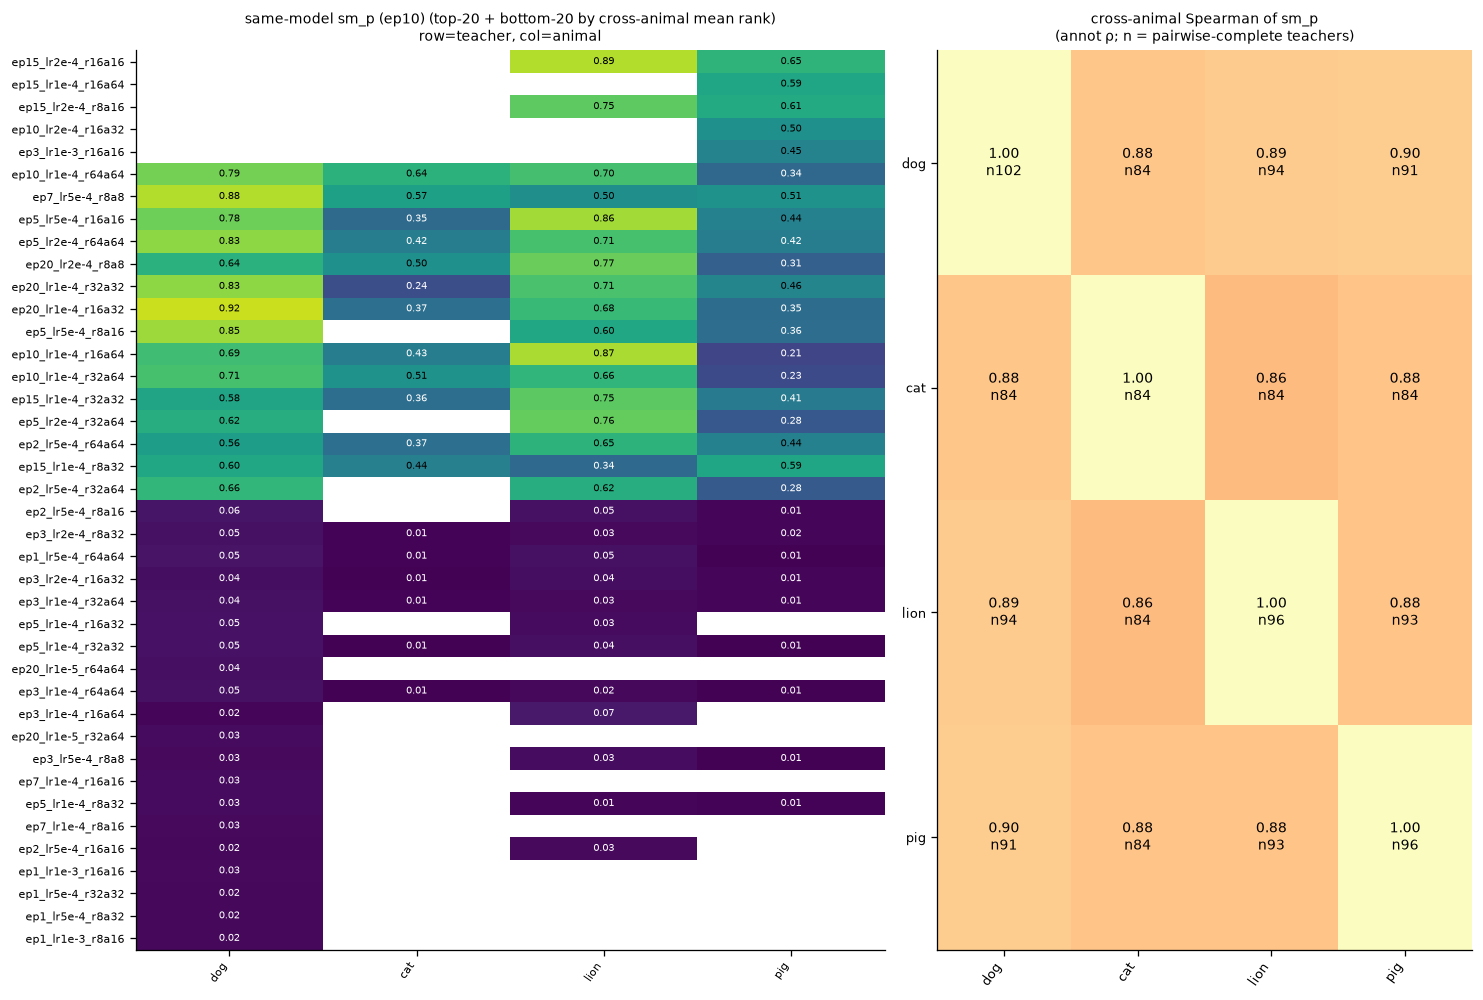

Cross-animal Spearman matrix (ALL teachers):


,dog,cat,lion,pig
dog,1.000,0.880,0.894,0.897
cat,0.880,1.000,0.859,0.876
lion,0.894,0.859,1.000,0.878
pig,0.897,0.876,0.878,1.000


Pairwise-complete teacher counts:


,dog,cat,lion,pig
dog,102,84,94,91
cat,84,84,84,84
lion,94,84,96,93
pig,91,84,93,96


In [15]:
SM_LADDER = tuple(f"ep{e}_lr1e-4_r8a32" for e in (1, 2, 5, 10, 20))
SM_CELL = "ep10_lr1e-4_r8a32"  # common across all four animals (ep20 is dog-only)
# param_tags=None -> discover EVERY same-model lineage on disk (drops the focus-20 restriction).
sm_all = tf.same_model_scores(OUTPUT_ROOT, None, student_cells=(SM_CELL,))
print("same-model lineages found per animal (ep10 std cell), ALL teachers:")
for a in tf.FOCUS_ANIMALS:
    sub = sm_all[sm_all.animal == a]
    ds = sub['dataset'].iloc[0] if len(sub) else '-'
    print(f"  {a:5s}: {len(sub):3d} teachers  (pool {ds})")

mat, gtab, nmat = tf.teacher_generality(sm_all, SM_CELL)
animals_g = list(mat.index)
n_all4 = int((gtab["n_animals"] == len(animals_g)).sum())
print(f"\n{n_all4} teachers are present in all {len(animals_g)} animals (fully shared).")

# Row-subset the sm_p heatmap when there are too many teachers to read.
sm_wide = gtab[animals_g]
note = ""
if len(sm_wide) > 40:
    sm_show = pd.concat([sm_wide.head(20), sm_wide.tail(20)])
    note = " (top-20 + bottom-20 by cross-animal mean rank)"
else:
    sm_show = sm_wide

fig, axes = plt.subplots(1, 2, figsize=(13, max(5, 0.22 * len(sm_show))),
                         gridspec_kw={"width_ratios": [1.4, 1]})
aplots.annotated_heatmap(axes[0], sm_show, cmap="viridis", vmin=0.0, vmax=1.0,
                         fmt="{:.2f}", origin="upper", cell_fontsize=6, tick_fontsize=7)
axes[0].set_title(f"same-model sm_p (ep10){note}\nrow=teacher, col=animal", fontsize=9)
aplots.annotated_heatmap(axes[1], mat, cmap="magma", vmin=0.0, vmax=1.0, counts=nmat.astype(int),
                         fmt="{:.2f}", origin="upper", cell_fontsize=9)
axes[1].set_title("cross-animal Spearman of sm_p\n(annot ρ; n = pairwise-complete teachers)",
                  fontsize=9)
plt.tight_layout(); plt.show()

print("Cross-animal Spearman matrix (ALL teachers):"); display(mat.round(3))
print("Pairwise-complete teacher counts:"); display(nmat.astype(int))

### 9b. Does same-model score predict cross-init transfer?

Two aggregations, stated explicitly:

- **Pooled scatter (below):** **row unit = one teacher within an animal.** x = same-model `sm_p`
  (ep10); y = that teacher's cross-init **unconditional mean test** (all seeds, threshold-free),
  **pooled = the mean over the landed student bases × the focus cells, every cell weighted
  equally**. Per-panel Pearson r / Spearman ρ / n; pooled within-animal partial r + p printed.
- **Per-(animal × base) table (§9b-ii):** the same correlation computed **within each landed
  (animal, base) arm** separately, so a strong base does not mask a weak one.

The focus-20 teachers are used here (only they have cross-init runs).

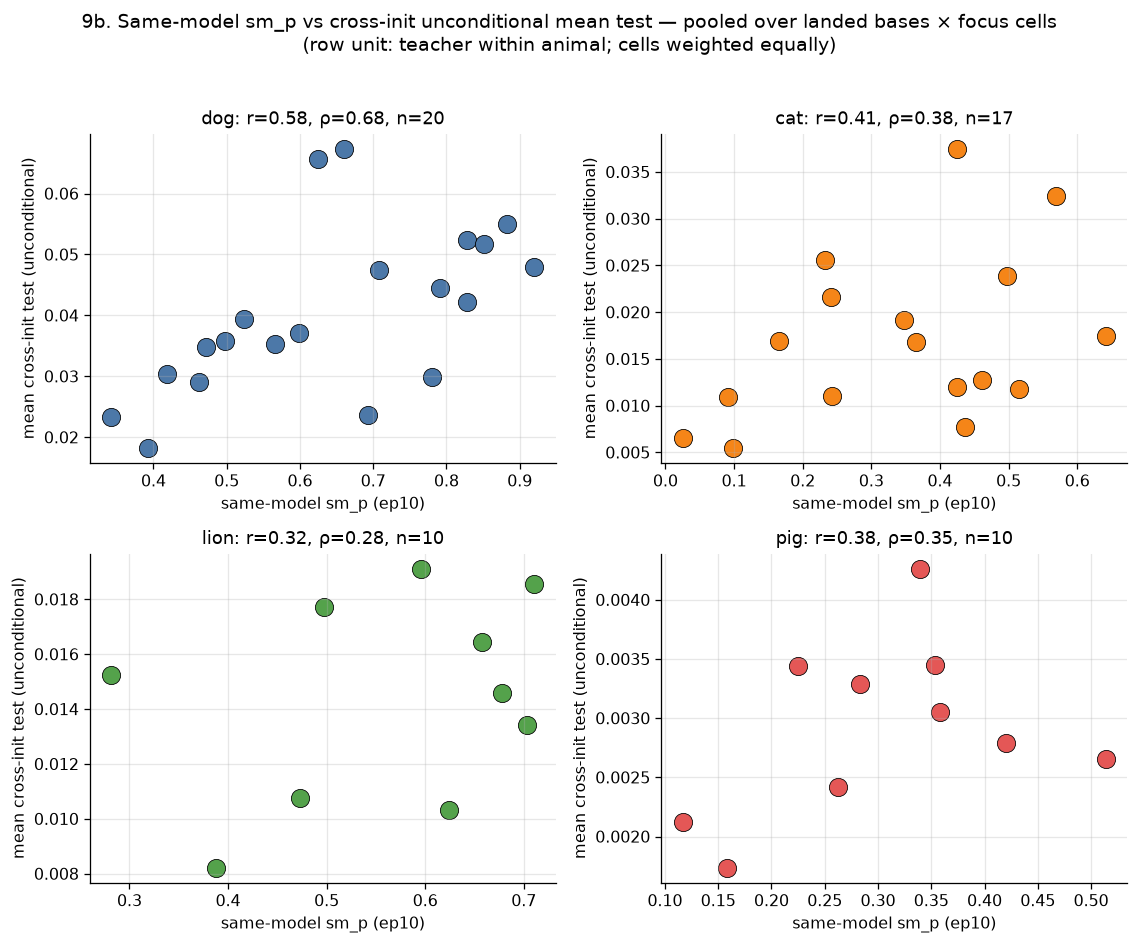

Unconditional mean-test response — per-animal + POOLED within-animal partial r:


,animal,r,rho,n,beta,p
0,cat,0.4102,0.3848,17,NaN,NaN
1,dog,0.5811,0.6797,20,NaN,NaN
2,lion,0.3190,0.2848,10,NaN,NaN
3,pig,0.3827,0.3455,10,NaN,NaN
4,POOLED,0.4652,NaN,57,0.0271,0.0004


POOLED (mean): partial r=0.465, β=0.0271, p=0.0004

partial r = Pearson correlation of the two variables after removing each animal's mean (both residualized on animal FEs); i.e. the within-animal association, immune to cross-animal level differences.


In [16]:
cov_sm = tf.teacher_covariates(OUTPUT_ROOT, PARAM_TAGS, samemodel_cell=SM_CELL)
f1_sm = tf.factor1_table(cells, cov_sm, covariate="samemodel_p", response="mean")

pt = (cells.groupby(["animal", "teacher_tag"])["mean_test"].mean().reset_index()
      .merge(cov_sm[["animal", "teacher_tag", "samemodel_p"]], on=["animal", "teacher_tag"])
      .dropna(subset=["mean_test", "samemodel_p"]))
landed = [a for a in tf.FOCUS_ANIMALS if (pt.animal == a).any()]
r_by = {row.animal: (row.r, row.rho, int(row.n)) for row in f1_sm.itertuples() if row.animal != "POOLED"}
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for ax, a in zip(axes.ravel(), landed):
    s = pt[pt.animal == a]
    ax.scatter(s.samemodel_p, s.mean_test, s=130, color=ANIMAL_COLORS.get(a, "#888"),
               edgecolor="k", linewidth=0.5)
    r, rho, n = r_by.get(a, (np.nan, np.nan, len(s)))
    ax.set_title(f"{a}: r={r:.2f}, ρ={rho:.2f}, n={n}", fontsize=11)
    ax.set_xlabel("same-model sm_p (ep10)"); ax.set_ylabel("mean cross-init test (unconditional)")
for ax in axes.ravel()[len(landed):]:
    ax.axis("off")
fig.suptitle("9b. Same-model sm_p vs cross-init unconditional mean test — pooled over landed "
             "bases × focus cells\n(row unit: teacher within animal; cells weighted equally)", y=1.02)
plt.tight_layout(); plt.show()

print("Unconditional mean-test response — per-animal + POOLED within-animal partial r:")
display(f1_sm.round(4))
pc = f1_sm.set_index("animal").loc["POOLED"]
print(f"POOLED (mean): partial r={pc['r']:.3f}, β={pc.get('beta', float('nan')):.4f}, "
      f"p={pc.get('p', float('nan')):.4f}")
print("\npartial r = Pearson correlation of the two variables after removing each animal's mean "
      "(both residualized on animal FEs); i.e. the within-animal association, immune to "
      "cross-animal level differences.")

#### 9b-ii. Same-model↔cross-init correlation *within each (animal × base) arm*

**Row unit of each correlation:** one teacher. Within each landed (animal, base) arm we correlate
teacher `sm_p` (ep10) against that teacher's **unconditional** mean test over the focus cells in
**that base only** (all seeds, threshold-free), reporting Pearson r, Spearman ρ, and n teachers.
This unpools the §9b scatter so a strong base cannot mask a weak one. Cells annotate ρ with n.

Per-(animal × base) same-model↔cross-init correlation (row unit: teacher within that arm):


,animal,base_label,r,rho,n
0,cat,data-seed1,0.241,0.431,17
1,cat,data-seed2,0.269,-0.024,8
2,cat,data-seed3,0.088,-0.071,8
3,cat,weight-seed1,0.383,0.181,17
4,cat,weight-seed2,-0.040,-0.214,8
5,cat,weight-seed3,0.010,-0.119,8
6,dog,data-seed1,0.322,0.358,20
7,dog,data-seed2,0.567,0.539,10
8,dog,data-seed3,0.591,0.406,10
9,dog,weight-seed1,0.395,0.420,20


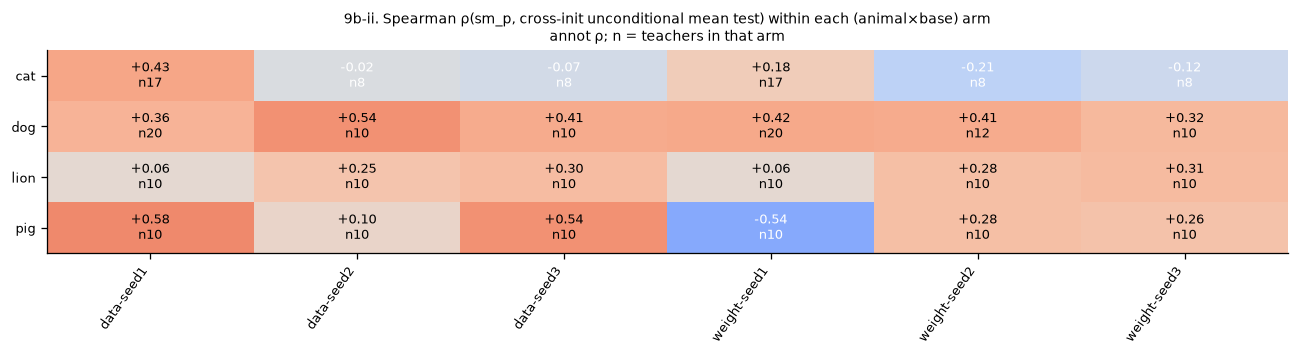

In [17]:
cond_bt = (cells.groupby(["animal", "base_label", "teacher_tag"])["mean_test"].mean().reset_index()
           .merge(cov_sm[["animal", "teacher_tag", "samemodel_p"]], on=["animal", "teacher_tag"])
           .dropna(subset=["mean_test", "samemodel_p"]))

def safe_corr(x, y):
    """``(pearson r, spearman rho)`` or ``(nan, nan)`` on a degenerate arm.

    Degenerate = fewer than 3 points, or either side constant (both make the correlation
    undefined); scipy would warn and return nan/0 inconsistently.
    """
    if len(x) >= 3 and x.nunique() > 1 and y.nunique() > 1:
        return float(pearsonr(x, y)[0]), float(spearmanr(x, y)[0])
    return np.nan, np.nan


rows_ab = []
for (a, b), g in cond_bt.groupby(["animal", "base_label"]):
    r, rho = safe_corr(g.samemodel_p, g.mean_test)
    rows_ab.append({"animal": a, "base_label": b, "r": round(r, 3), "rho": round(rho, 3),
                    "n": len(g)})
ab_tab = pd.DataFrame(rows_ab).sort_values(["animal", "base_label"]).reset_index(drop=True)
print("Per-(animal × base) same-model↔cross-init correlation (row unit: teacher within that arm):")
display(ab_tab)

rho_grid = ab_tab.pivot(index="animal", columns="base_label", values="rho")
n_grid = ab_tab.pivot(index="animal", columns="base_label", values="n")
cols_o = present_bases(rho_grid.columns)
rho_grid, n_grid = rho_grid[cols_o], n_grid[cols_o]
fig, ax = plt.subplots(figsize=(1.4 * len(cols_o) + 3, 3.2))
aplots.annotated_heatmap(ax, rho_grid, cmap="coolwarm", vmin=-1.0, vmax=1.0, mid=0.0,
                         counts=n_grid.fillna(0).astype(int), fmt="{:+.2f}", origin="upper",
                         cell_fontsize=8)
ax.set_title("9b-ii. Spearman ρ(sm_p, cross-init unconditional mean test) within each "
             "(animal×base) arm\n"
             "annot ρ; n = teachers in that arm", fontsize=9)
plt.tight_layout(); plt.show()

#### 9b-iii. Is the teacher strength order the same across student bases?

**Question:** does a teacher that transfers well into ds1 also transfer well into ws2? For each
animal with ≥2 landed bases we build the **base × base Spearman matrix** of per-teacher
**unconditional** mean cross-init test (all seeds, threshold-free; pairwise-complete teachers,
n annotated). Then a **pooled** version whose unit
is the (animal, teacher) pair, so it reads the base-to-base order agreement across all animals at
once. Animals with <2 landed bases are skipped (stated).

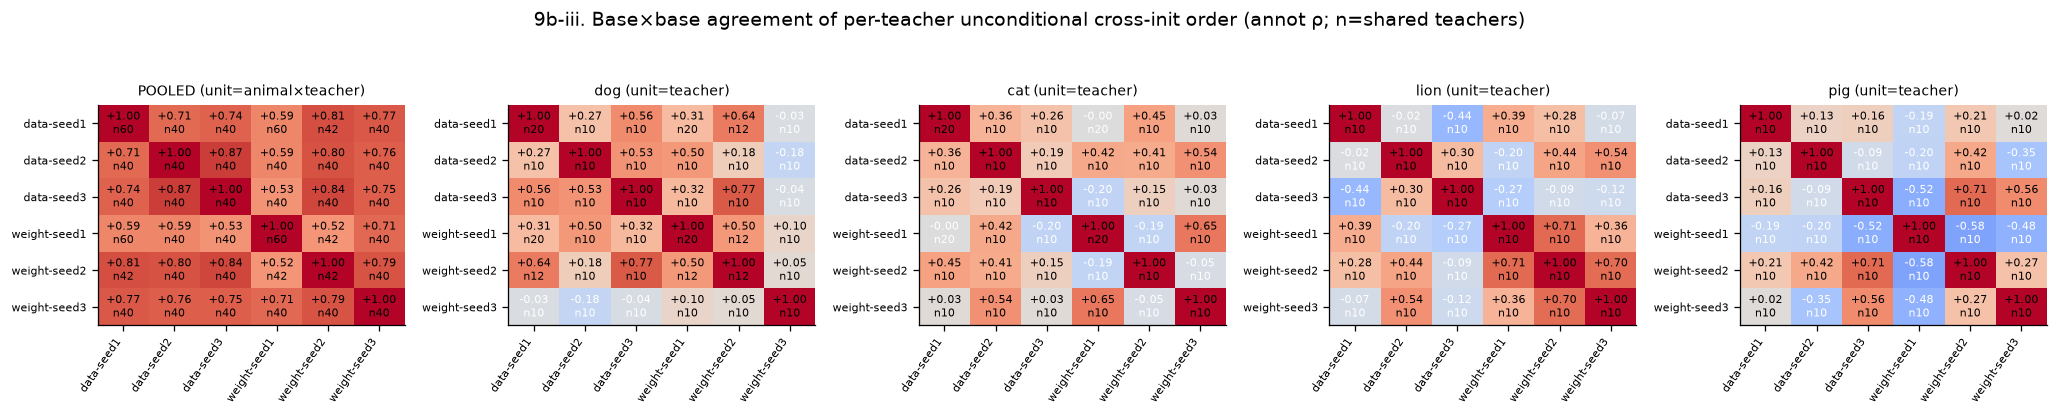

POOLED base×base Spearman ρ:


,data-seed1,data-seed2,data-seed3,weight-seed1,weight-seed2,weight-seed3
data-seed1,1.000,0.711,0.738,0.589,0.812,0.774
data-seed2,0.711,1.000,0.868,0.593,0.798,0.756
data-seed3,0.738,0.868,1.000,0.526,0.838,0.755
weight-seed1,0.589,0.593,0.526,1.000,0.521,0.715
weight-seed2,0.812,0.798,0.838,0.521,1.000,0.789
weight-seed3,0.774,0.756,0.755,0.715,0.789,1.000


POOLED pairwise n (shared animal×teacher units):


,data-seed1,data-seed2,data-seed3,weight-seed1,weight-seed2,weight-seed3
data-seed1,60,40,40,60,42,40
data-seed2,40,40,40,40,40,40
data-seed3,40,40,40,40,40,40
weight-seed1,60,40,40,60,42,40
weight-seed2,42,40,40,42,42,40
weight-seed3,40,40,40,40,40,40


In [18]:
# Pooled across animals: unit = (animal, teacher), matrix over bases.
rho_pool, n_pool = tf.teacher_order_agreement(cells, by="base_label", value="mean_test",
                                              unit=("animal", "teacher_tag"))
cols_p = present_bases(rho_pool.columns)
rho_pool, n_pool = rho_pool.loc[cols_p, cols_p], n_pool.loc[cols_p, cols_p]

by_animal = {}
for a in tf.FOCUS_ANIMALS:
    ca = cells[cells.animal == a]
    nb = ca["base_label"].nunique()
    if nb >= 2:
        rho_a, n_a = tf.teacher_order_agreement(ca, by="base_label", value="mean_test", unit=("teacher_tag",))
        cols_a = present_bases(rho_a.columns)
        by_animal[a] = (rho_a.loc[cols_a, cols_a], n_a.loc[cols_a, cols_a])
    else:
        print(f"  {a}: only {nb} landed base(s) — skipped (need >=2)")

panels = [("POOLED (unit=animal×teacher)", rho_pool, n_pool)] + \
         [(f"{a} (unit=teacher)", r, n) for a, (r, n) in by_animal.items()]
fig, axes = plt.subplots(1, len(panels), figsize=(3.6 * len(panels), 3.4), squeeze=False)
for ax, (title, r, n) in zip(axes[0], panels):
    aplots.annotated_heatmap(ax, r, cmap="coolwarm", vmin=-1.0, vmax=1.0, mid=0.0,
                             counts=n.fillna(0).astype(int), fmt="{:+.2f}", origin="upper",
                             cell_fontsize=7, tick_fontsize=7)
    ax.set_title(title, fontsize=9)
fig.suptitle("9b-iii. Base×base agreement of per-teacher unconditional cross-init order "
             "(annot ρ; n=shared teachers)",
             y=1.05)
plt.tight_layout(); plt.show()
print("POOLED base×base Spearman ρ:"); display(rho_pool.round(3))
print("POOLED pairwise n (shared animal×teacher units):"); display(n_pool.astype(int))

> **SELECTION CAVEAT (read before interpreting 9b).** The 20 teachers *are* dog's top-20 by
> exactly this screen (single-ftseed, same-model **ep20**). So the **dog** panel is
> **range-restricted** — only the top of dog's ranking is present — and its same-model↔cross-init
> correlation is **attenuated** by construction. cat / lion / pig scores played **no role** in
> selecting these teachers, so those panels are the **clean read** of whether same-model quality
> predicts cross-init transfer.

## 10. Interpretation — what can and cannot be concluded now

- **Coverage is partial.** Several arms (weight-seed3, data-seed3 for most animals; lion/pig
  beyond ds1/ws1) are thin or absent, so the within-animal cross-base contrast rests on ~15
  (animal × base) points. The permutation test is the honest inference at this n.
- **The prior verdict** printed in §5 is the headline: whether the measured student-base prior
  (logprob and behavioral) explains within-animal cross-base transfer, net of animal and base
  fixed effects. Read the permutation p, not the cluster-robust p.
- **Factor 1** (teacher imprint) uses a tseed-averaged proxy for the tseed-1 campaign teachers;
  treat per-animal correlations as indicative.
- **All fits are threshold-free** as of 2026-08-19: §5–§7/§9b responses are the unconditional
  mean-test logit over all seeds; collapse is read only on the integrity channel (§4). Numbers
  quoted from earlier runs (conditional-transfer responses at the legacy `DEAD=0.005` p(trait)
  scalar) are superseded by this run's printed outputs.
- **Same-model quality (§9)** partially predicts cross-init transfer — the pooled
  within-animal partial r is positive and significant — but the effect is carried by cat/dog while
  lion/pig are near-null, and dog is range-restricted by the selection screen, so this is a
  qualified "yes, weakly" rather than a clean law. Across the FULL teacher range (§9a) same-model
  quality agrees strongly cross-animal (ρ≈0.86–0.90); the focus-20 truncation to dog's top slice
  is what deflated it.
- **Teacher order across bases (§9b-iii)** is positively but only moderately correlated
  (pooled base×base ρ mostly 0.3–0.8) — the teacher that transfers best is somewhat, not fully,
  base-invariant.
- **ds-vs-ws** rests on 2–3 bases per group — a group-mean difference is suggestive only.
- This notebook is **re-run-to-update**: as arms drain, re-execute top-to-bottom and every table,
  figure, and verdict refreshes from disk with no code change.